# TCC — Análise Comparativa e Estatística

**Mitigação de Débito Técnico Estrutural — Spring PetClinic REST**

Compara três versões da aplicação (Baseline, Baseline Degradada, Pós-Refatoração) combinando métricas estáticas (PMD, ArchUnit), dinâmicas (K6) e tratamento estatístico (Mann-Whitney U, Cliff's Delta).


In [1]:
# --- Bibliotecas e configuração global -------------------------------------
import os
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, HTML

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

def legenda(texto: str):
    """Exibe uma legenda/descrição em itálico logo abaixo de uma tabela ou figura,
    no padrão 'Tabela X — descrição' usado no corpo do TCC."""
    display(Markdown(f"<div style='font-size:0.85em;color:#555;margin-top:4px'><i>{texto}</i></div>"))

In [2]:
# ── Hiperparâmetro: selecione o cenário de carga ─────────────────────────────
# Valores válidos: "uv26" (26 usuários virtuais) | "uv12" (12 usuários virtuais)
UV_CENARIO = "uv26"  # ← altere aqui para trocar o conjunto de dados do K6

assert UV_CENARIO in {"uv26", "uv12"}, "UV_CENARIO deve ser 'uv26' ou 'uv12'"
print(f"Processando dados K6: {UV_CENARIO}")

# Pasta de saída para figuras (.png, 300 DPI) e planilhas (.xlsx)
# Agora parametrizada pelo UV_CENARIO para evitar sobrescrever dados de cenários diferentes
OUTPUT_DIR = Path(f"resultados_estatisticos_{UV_CENARIO}")
OUTPUT_DIR.mkdir(exist_ok=True)

Processando dados K6: uv26


## 1. Configuração dos Cenários

Define as _branches_ do experimento e localiza os arquivos de dados.


In [3]:
BASE_DIR = Path("data")
N_RUNS_ESPERADO = 5

# ── Globs parametrizados por UV_CENARIO ──────────────────────────────────────
def _k6_glob(prefix: str, uv: str) -> tuple[str, str]:
    """Retorna (csv_glob, json_glob) adaptados ao cenário de carga."""
    sufixo = f"-rate-{uv[2:]}" if uv == "uv12" else ""  # uv12 → -rate-12; uv26 → ""
    subdir = f"k6/{uv}"
    csv_glob  = f"{subdir}/k6-metrics-{prefix}{sufixo}_run_*.csv"
    json_glob = f"{subdir}/k6-summary-{prefix}{sufixo}_run_*.json"
    return csv_glob, json_glob

_b_csv,  _b_json  = _k6_glob("refactoring-metrics", UV_CENARIO)
_d_csv,  _d_json  = _k6_glob("refactoring-metrics-intentional-code-smells", UV_CENARIO)
_r_csv,  _r_json  = _k6_glob("refactoring-metrics-pos-refactoring", UV_CENARIO)

# Ordem lógica: Baseline → Baseline Degradada → Pós-Refatoração
SCENARIOS = {
    "baseline": {
        "label": "Baseline",
        "color": "#4dabf7",
        "k6_csv_glob":  _b_csv,
        "k6_json_glob": _b_json,
        "pmd_csv":      "pmd/pmd-refactoring-metrics.csv",
        "archunit_txt": "archunit/refactoring-metrics-archunit.txt",
    },
    "degradada": {
        "label": "Baseline Degradada",
        "color": "#ff6b6b",
        "k6_csv_glob":  _d_csv,
        "k6_json_glob": _d_json,
        "pmd_csv":      "pmd/pmd-refactoring-metrics-intentional-code-smells.csv",
        "archunit_txt": "archunit/refactoring-metrics-intentional-code-smells-archunit.txt",
    },
    "refatorada": {
        "label": "Pós-Refatoração",
        "color": "#51cf66",
        "k6_csv_glob":  _r_csv,
        "k6_json_glob": _r_json,
        "pmd_csv":      "pmd/pmd-refactoring-metrics-pos-refactoring.csv",
        "archunit_txt": "archunit/refactoring-metrics-pos-refactoring-archunit.txt",
    },
}

ORDEM_CENARIOS = [v["label"] for v in SCENARIOS.values()]
PALETA = {v["label"]: v["color"] for v in SCENARIOS.values()}


## 2. Ingestão dos Dados K6 (CSV)

Carrega os arquivos `.csv` do K6 para o cenário `UV_CENARIO` selecionado.


In [4]:
# Métricas do K6 relevantes para latência, contagem de requisições e falhas
METRICAS_INTERESSE = {"http_req_duration", "http_reqs", "http_req_failed"}

# Colunas efetivamente usadas (lidas seletivamente para reduzir memória/tempo de parsing)
K6_CSV_USECOLS = ["metric_name", "timestamp", "metric_value", "name", "group", "scenario"]
K6_CSV_DTYPES = {"metric_name": "category", "name": "category", "group": "category", "scenario": "category"}


def carregar_k6_csv_run(filepath: Path, run_number: int, chunksize: int = 500_000) -> pd.DataFrame:
    """Lê um CSV bruto do K6 em blocos, mantendo somente as métricas de interesse
    e apenas a fase de regime estável (scenario == 'steady_state')."""
    if not filepath or not Path(filepath).exists():
        return pd.DataFrame()

    chunks_filtrados = []
    try:
        leitor = pd.read_csv(
            filepath,
            usecols=lambda c: c in K6_CSV_USECOLS,
            dtype={k: v for k, v in K6_CSV_DTYPES.items() if k in K6_CSV_USECOLS},
            chunksize=chunksize,
            low_memory=False,
            on_bad_lines="skip",
        )
        for chunk in leitor:
            if "metric_name" not in chunk.columns:
                continue
            chunk = chunk[chunk["metric_name"].isin(METRICAS_INTERESSE)]
            # Exclui a fase de warm-up: só a fase 'steady_state' representa o regime avaliado
            if "scenario" in chunk.columns:
                chunk = chunk[chunk["scenario"] == "steady_state"]
            # Exclui o grupo de checagem de saúde pré-teste
            if "group" in chunk.columns:
                chunk = chunk[chunk["group"].astype(str) != "::setup"]
            if not chunk.empty:
                chunks_filtrados.append(chunk)
    except Exception as exc:
        print(f"  [aviso] falha ao ler {filepath.name}: {exc}")
        return pd.DataFrame()

    if not chunks_filtrados:
        return pd.DataFrame()

    df = pd.concat(chunks_filtrados, ignore_index=True)
    df["run"] = run_number
    df["metric_value"] = pd.to_numeric(df["metric_value"], errors="coerce")
    df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
    df = df.drop(columns=["scenario"])  # já cumpriu seu papel de filtro
    return df.dropna(subset=["metric_value", "timestamp"])


def consolidar_k6_csv_cenario(csv_files: list) -> pd.DataFrame:
    """Concatena as N execuções de um cenário em um único DataFrame, numerando cada run."""
    dfs = []
    for i, fp in enumerate(csv_files, start=1):
        run_match = re.search(r"run_(\d+)", fp.name)
        run_number = int(run_match.group(1)) if run_match else i
        df_run = carregar_k6_csv_run(fp, run_number)
        if not df_run.empty:
            dfs.append(df_run)
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


dados_k6 = {}
for nome_cenario, cfg in SCENARIOS.items():
    csv_files = sorted(BASE_DIR.glob(cfg["k6_csv_glob"]))
    dados_k6[nome_cenario] = consolidar_k6_csv_cenario(csv_files)
    n_linhas = len(dados_k6[nome_cenario])
    n_runs_lidos = dados_k6[nome_cenario]["run"].nunique() if n_linhas else 0
    print(f"{cfg['label']:<20} → {n_linhas:>10,} pontos de dado (steady_state) em {n_runs_lidos} execuções")

Baseline             →    600,564 pontos de dado (steady_state) em 5 execuções
Baseline Degradada   →    281,088 pontos de dado (steady_state) em 5 execuções
Pós-Refatoração      →    714,939 pontos de dado (steady_state) em 5 execuções


### 2.1 Sumários JSON

Carrega os arquivos `summary.json` com throughput, erros e saturação pré-computados.


In [5]:
# Mapa de endpoints -> rótulo amigável (mesma nomenclatura usada no CSV, sem "::")
ENDPOINTS_LABEL = {
    "GET /owners": "GET /owners",
    "POST /owners": "POST /owners",
    "GET /owners/{ownerId}": "GET /owners/{id}",
    "POST /owners/{ownerId}/pets": "POST /owners/{id}/pets",
    "POST /owners/{ownerId}/pets/{petId}/visits": "POST /owners/{id}/pets/{pid}/visits",
    "GET /vets": "GET /vets",
}


def carregar_k6_json_run(filepath: Path) -> dict:
    with open(filepath, "r", encoding="utf-8") as f:
        return json.load(f)


registros_execucao = []
for cenario_key, cfg in SCENARIOS.items():
    for fp in sorted(BASE_DIR.glob(cfg["k6_json_glob"])):
        run_match = re.search(r"run_(\d+)", fp.name)
        run_number = int(run_match.group(1)) if run_match else 0

        summary = carregar_k6_json_run(fp)
        meta = summary.get("meta", {})
        glob = summary.get("global", {})
        resumo = summary.get("resumo_por_endpoint", {})

        # raw.metrics ainda é necessário para taxas globais (http_reqs.rate, iterations.rate etc.)
        raw_metrics = summary.get("raw", {}).get("metrics", {})

        def taxa(metric_name):
            return raw_metrics.get(metric_name, {}).get("values", {}).get("rate", np.nan)

        registro = {
            "cenario": cenario_key,
            "cenario_label": cfg["label"],
            "run": run_number,
            "executor": meta.get("executor"),
            "taxa_alvo_reqs_s": meta.get("rate_por_segundo"),
            "duracao_min": summary.get("raw", {}).get("state", {}).get("testRunDurationMs", 0) / 1000 / 60,
            "throughput_http_reqs_s": taxa("http_reqs"),
            "throughput_iteracoes_s": taxa("iterations"),
            "taxa_erro_global": glob.get("taxa_erro_global", {}).get("rate", np.nan),
            "dropped_iterations": glob.get("dropped_iterations", {}).get("count", 0),
            "owners_criados_sucesso": glob.get("counters", {}).get("owners_criados_com_sucesso", np.nan),
            "pets_criados_sucesso": glob.get("counters", {}).get("pets_criados_com_sucesso", np.nan),
            "visits_criadas_sucesso": glob.get("counters", {}).get("visits_criadas_com_sucesso", np.nan),
        }

        # p95 por endpoint (cruzamento/validação — fonte oficial é o CSV, Seção 3)
        for ep_full, ep_label in ENDPOINTS_LABEL.items():
            lat = resumo.get(ep_full, {}).get("latencia_ms", {})
            registro[f"p95_json_{ep_label}"] = lat.get("p95", np.nan)

        registros_execucao.append(registro)

df_execucoes = pd.DataFrame(registros_execucao)
print(f"Sumários JSON carregados: {len(df_execucoes)} execuções "
      f"({df_execucoes['cenario'].nunique()} cenários)")

Sumários JSON carregados: 15 execuções (3 cenários)


## 3. Visão Geral por Execução (Run)

Percentis de latência global (min, média, mediana, p90, p95, p99, max) por rodada.


In [6]:
def metricas_por_run(dados_k6: dict) -> pd.DataFrame:
    """Calcula min/média/mediana/p90/p95/p99/max de latência global por execução (run)."""
    linhas = []
    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue
        df_lat = df[df["metric_name"] == "http_req_duration"]
        if df_lat.empty:
            continue

        for run, serie in df_lat["metric_value"].groupby(df_lat["run"]):
            linhas.append({
                "cenario": SCENARIOS[nome_cenario]["label"],
                "run": run,
                "n_reqs": len(serie),
                "min_ms": serie.min(),
                "media_ms": serie.mean(),
                "mediana_ms": serie.median(),
                "p90_ms": serie.quantile(0.90),
                "p95_ms": serie.quantile(0.95),
                "p99_ms": serie.quantile(0.99),
                "max_ms": serie.max(),
            })
    return pd.DataFrame(linhas)


df_runs = metricas_por_run(dados_k6)

for cenario in ORDEM_CENARIOS:
    df_sub = df_runs[df_runs["cenario"] == cenario]
    if df_sub.empty:
        continue
    display(Markdown(f"#### {cenario} — latência global por execução (ms, fase *steady_state*)"))
    tabela = df_sub.drop(columns=["cenario"]).sort_values("run").set_index("run")
    display(tabela.style.format("{:,.2f}").format({"n_reqs": "{:,.0f}"}))

legenda("Tabela 1 — Latência global (todas as requisições, todos os endpoints) por execução "
        "e cenário, calculada a partir do CSV bruto do K6 filtrado para a fase steady_state. "
        "p95/p99 em milissegundos.")

# Exportação para Excel
df_runs.to_excel(OUTPUT_DIR / "tabela_01_latencia_global_por_run.xlsx",
                  sheet_name="Tabela_01_Latencia_Global", index=False)
print(f"Tabela 1 exportada para: {(OUTPUT_DIR / 'tabela_01_latencia_global_por_run.xlsx').resolve()}")

#### Baseline — latência global por execução (ms, fase *steady_state*)

,n_reqs,min_ms,media_ms,mediana_ms,p90_ms,p95_ms,p99_ms,max_ms
run,,,,,,,,
1,"41,187",0.755761,4715.642724,4186.179898,9984.146233,12228.024759,16904.727507,33479.645412
2,"39,592",0.781614,4883.711976,4517.907042,10030.985873,12213.132134,17310.519055,33977.759107
3,"40,034",0.730783,4865.132592,4621.672135,9895.902311,12029.488915,16752.713664,33088.931678
4,"39,602",0.709850,4911.547743,4594.239577,9921.277307,12203.839080,16940.533978,35293.509153
5,"39,773",0.744340,4849.517592,4532.096381,9900.503092,12239.199507,17256.012970,39370.508468


#### Baseline Degradada — latência global por execução (ms, fase *steady_state*)

,n_reqs,min_ms,media_ms,mediana_ms,p90_ms,p95_ms,p99_ms,max_ms
run,,,,,,,,
1,"19,286",0.892191,10579.370342,3440.790756,41460.956604,60000.408548,60001.190242,60010.323393
2,"18,520",0.913853,11211.501829,3791.943648,43130.341624,60000.517931,60001.160501,60010.544615
3,"18,904",0.920987,10458.908242,2564.302190,44690.138082,60000.439414,60001.167845,60011.329492
4,"18,634",0.861778,10977.733992,3507.134751,39966.638385,60000.435401,60001.161258,60003.544158
5,"18,352",1.037955,11121.754087,3950.633943,41718.695415,60000.537753,60001.180974,60003.383164


#### Pós-Refatoração — latência global por execução (ms, fase *steady_state*)

,n_reqs,min_ms,media_ms,mediana_ms,p90_ms,p95_ms,p99_ms,max_ms
run,,,,,,,,
1,"48,140",0.452901,3487.641056,1882.074753,9644.546812,12251.879393,17666.323820,34693.855574
2,"47,246",0.467403,3508.568764,1933.874289,9616.071297,12097.267900,17457.751314,34429.662907
3,"47,690",0.474243,3589.836691,2088.447286,9577.796202,11912.570733,17139.130265,35909.323994
4,"47,547",0.388514,3670.208757,2211.080794,9595.749973,12180.044126,17278.134632,35011.781773
5,"47,690",0.512630,3594.462743,2105.177346,9558.482637,11985.924493,17379.765441,34283.321196


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 1 — Latência global (todas as requisições, todos os endpoints) por execução e cenário, calculada a partir do CSV bruto do K6 filtrado para a fase steady_state. p95/p99 em milissegundos.</i></div>

Tabela 1 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_01_latencia_global_por_run.xlsx


### 3.1 Throughput, Erros e Saturação

Cruzamento com o `summary.json`: vazão, taxa de erros e `dropped_iterations`.


In [7]:
colunas_execucao = [
    "run", "throughput_http_reqs_s", "throughput_iteracoes_s",
    "taxa_erro_global", "dropped_iterations",
    "owners_criados_sucesso", "pets_criados_sucesso", "visits_criadas_sucesso",
]

frames_tab2 = []
for cenario_key, cfg in SCENARIOS.items():
    df_sub = df_execucoes[df_execucoes["cenario"] == cenario_key].copy()
    if df_sub.empty:
        continue
    display(Markdown(f"#### {cfg['label']} — throughput, erros e saturação por execução"))
    tabela = df_sub[colunas_execucao].sort_values("run").set_index("run")
    tabela.loc["Média"] = tabela.mean()
    styled = tabela.style.format({
        "throughput_http_reqs_s": "{:,.2f}",
        "throughput_iteracoes_s": "{:,.2f}",
        "taxa_erro_global": "{:.4f}",
        "dropped_iterations": "{:,.0f}",
        "owners_criados_sucesso": "{:,.0f}",
        "pets_criados_sucesso": "{:,.0f}",
        "visits_criadas_sucesso": "{:,.0f}",
    })
    display(styled)
    # Acumula para exportação
    df_export = df_sub[colunas_execucao].sort_values("run").copy()
    df_export.insert(0, "cenario", cfg["label"])
    frames_tab2.append(df_export)

legenda("Tabela 2 — Vazão (req/s e iterações/s), taxa de erro global (fração, 4 casas "
        "decimais) e contagem de iterações descartadas (dropped_iterations, indicador de "
        "saturação) por execução, extraídos do summary.json.")

# Exportação para Excel
if frames_tab2:
    df_tab2_export = pd.concat(frames_tab2, ignore_index=True)
    df_tab2_export.to_excel(OUTPUT_DIR / "tabela_02_throughput_erros_saturacao_por_run.xlsx",
                             sheet_name="Tabela_02_Throughput_Erros", index=False)
    print(f"Tabela 2 exportada para: {(OUTPUT_DIR / 'tabela_02_throughput_erros_saturacao_por_run.xlsx').resolve()}")

#### Baseline — throughput, erros e saturação por execução

,throughput_http_reqs_s,throughput_iteracoes_s,taxa_erro_global,dropped_iterations,owners_criados_sucesso,pets_criados_sucesso,visits_criadas_sucesso
run,,,,,,,
1,56.56,7.91,0.0000,"12,753","6,257","6,201","6,141"
2,54.48,7.61,0.0000,"12,917","6,041","5,944","5,908"
3,55.07,7.71,0.0000,"12,927","6,082","6,032","5,986"
4,54.49,7.62,0.0000,"12,943","6,042","5,953","5,916"
5,54.72,7.65,0.0000,"12,902","6,058","5,984","5,940"
Média,55.07,7.70,0.0000,"12,888","6,096","6,023","5,978"


#### Baseline Degradada — throughput, erros e saturação por execução

,throughput_http_reqs_s,throughput_iteracoes_s,taxa_erro_global,dropped_iterations,owners_criados_sucesso,pets_criados_sucesso,visits_criadas_sucesso
run,,,,,,,
1,27.92,3.95,0.0576,"15,765","3,130","3,019","3,019"
2,26.92,3.77,0.0659,"15,840","2,965","2,946","2,882"
3,27.41,3.79,0.0596,"15,821","3,013","3,012","3,012"
4,27.07,3.78,0.0602,"15,897","2,969","2,969","2,969"
5,26.69,3.64,0.0658,"15,934","3,008","3,005","2,820"
Média,27.20,3.78,0.0618,"15,851","3,017","2,990","2,940"


#### Pós-Refatoração — throughput, erros e saturação por execução

,throughput_http_reqs_s,throughput_iteracoes_s,taxa_erro_global,dropped_iterations,owners_criados_sucesso,pets_criados_sucesso,visits_criadas_sucesso
run,,,,,,,
1,65.64,9.31,0.0000,"11,814","7,185","7,182","7,177"
2,64.46,9.07,0.0000,"11,845","7,118","7,043","7,001"
3,65.01,9.24,0.0000,"11,875","7,114","7,112","7,110"
4,64.83,9.25,0.0000,"11,906","7,092","7,091","7,090"
5,65.03,9.25,0.0000,"11,878","7,114","7,112","7,112"
Média,64.99,9.22,0.0000,"11,864","7,125","7,108","7,098"


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 2 — Vazão (req/s e iterações/s), taxa de erro global (fração, 4 casas decimais) e contagem de iterações descartadas (dropped_iterations, indicador de saturação) por execução, extraídos do summary.json.</i></div>

Tabela 2 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_02_throughput_erros_saturacao_por_run.xlsx


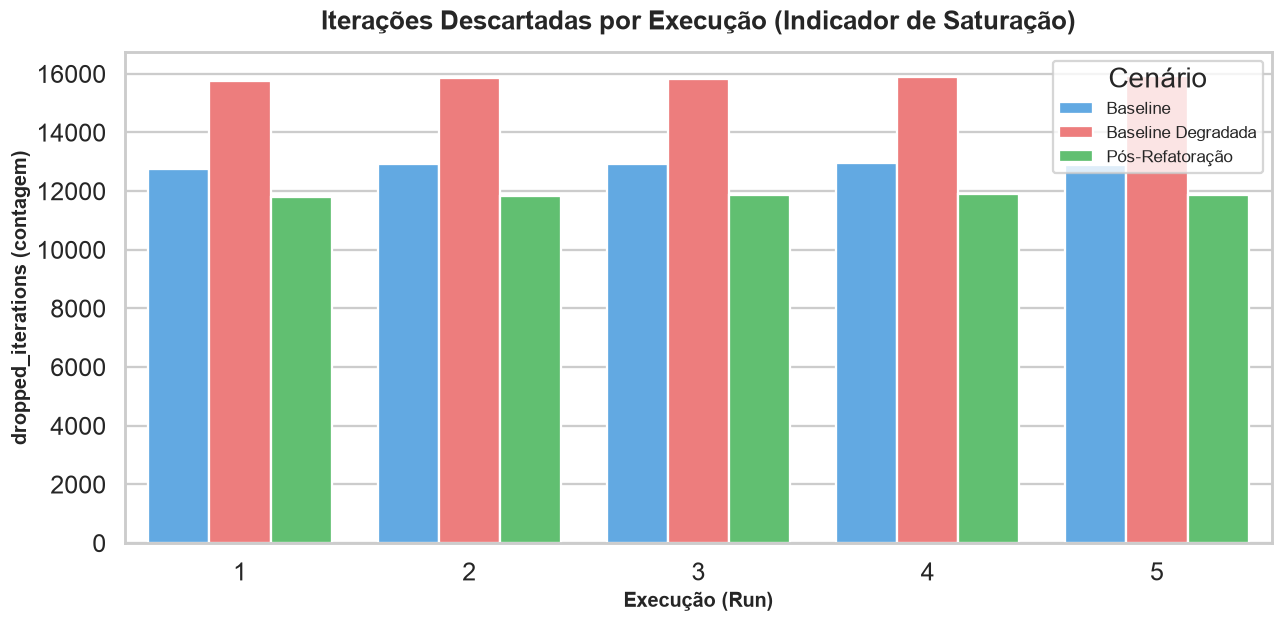

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 1 — Iterações descartadas pelo K6 (dropped_iterations) por execução e cenário. Valores consistentemente altos indicam que a branch não sustentou a taxa de disparo de 26 it/s (saturação real da aplicação sob o executor open-loop), e não um artefato de configuração do teste.</i></div>

In [8]:
# Gráfico de barras: iterações descartadas por execução e cenário — visão rápida de saturação
plt.figure(figsize=(12, 6))
df_sat = df_execucoes.copy()
df_sat["cenario_label"] = pd.Categorical(df_sat["cenario_label"], categories=ORDEM_CENARIOS, ordered=True)
ax = sns.barplot(
    data=df_sat, x="run", y="dropped_iterations", hue="cenario_label",
    palette=PALETA, order=sorted(df_sat["run"].unique())
)
plt.title("Iterações Descartadas por Execução (Indicador de Saturação)", fontsize=17, pad=15)
plt.xlabel("Execução (Run)", fontsize=13, fontweight="bold")
plt.ylabel("dropped_iterations (contagem)", fontsize=13, fontweight="bold")
plt.legend(title="Cenário", fontsize=11)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figura_01_saturacao_dropped_iterations.png", dpi=300)
plt.show()

legenda("Figura 1 — Iterações descartadas pelo K6 (dropped_iterations) por execução e "
        "cenário. Valores consistentemente altos indicam que a branch não sustentou a taxa "
        "de disparo de 26 it/s (saturação real da aplicação sob o executor open-loop), e "
        "não um artefato de configuração do teste.")

In [9]:
# Endpoints avaliados nas visualizações de latência (rótulo do CSV -> nome amigável)
ENDPOINTS_VALIDOS = {
    "::GET /owners": "GET /owners",
    "::GET /owners/{ownerId}": "GET /owners/{id}",
    "::GET /vets": "GET /vets",
    "::POST /owners": "POST /owners",
    "::POST /owners/{ownerId}/pets": "POST /owners/{id}/pets",
    "::POST /owners/{ownerId}/pets/{petId}/visits": "POST /owners/{id}/pets/{pid}/visits",
}


def montar_df_latencia_por_endpoint(dados_k6: dict) -> pd.DataFrame:
    """Concatena a latência (http_req_duration) de todos os cenários, rotulada por
    Cenário e Endpoint (nomes por extenso), pronta para plotagem com seaborn."""
    frames = []
    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue
        df_lat = df[df["metric_name"] == "http_req_duration"].copy()
        df_lat = df_lat[df_lat["group"].isin(ENDPOINTS_VALIDOS.keys())]
        df_lat["Cenário"] = SCENARIOS[nome_cenario]["label"]
        df_lat["Endpoint"] = df_lat["group"].map(ENDPOINTS_VALIDOS)
        frames.append(df_lat)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


DF_LATENCIA = montar_df_latencia_por_endpoint(dados_k6)
DF_LATENCIA["Cenário"] = pd.Categorical(DF_LATENCIA["Cenário"], categories=ORDEM_CENARIOS, ordered=True)
print(f"Dataset consolidado de latência por endpoint: {len(DF_LATENCIA):,} pontos")

Dataset consolidado de latência por endpoint: 457,324 pontos


### 3.2 Distribuição de Latência — Boxplots

Boxplots por cenário e endpoint; evidencia cauda longa e outliers.


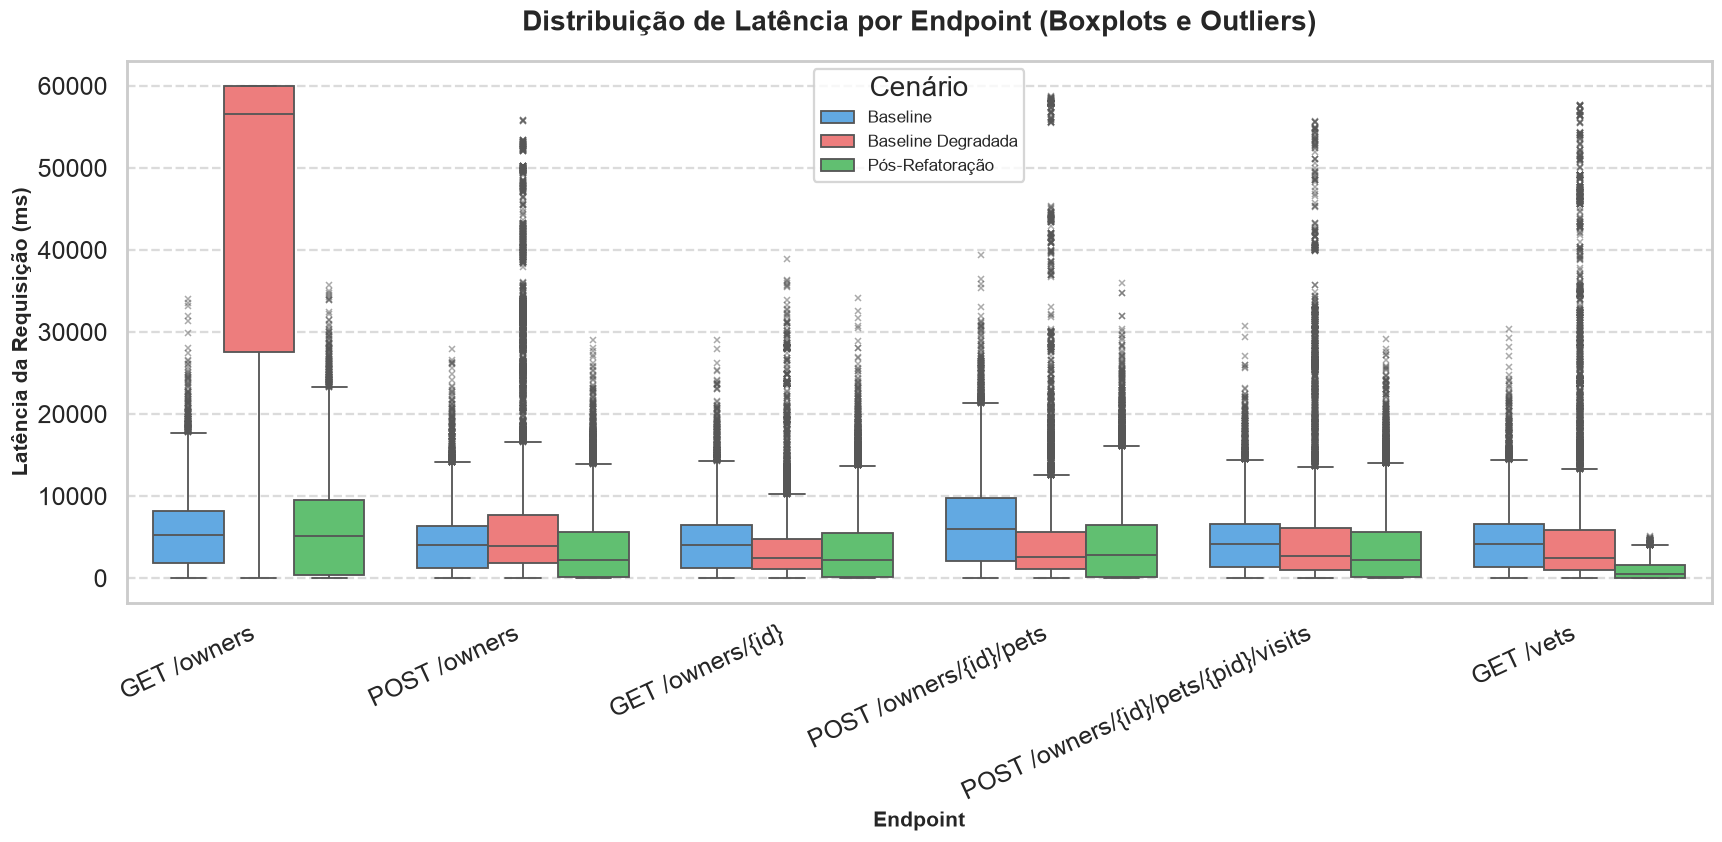

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 2 — Distribuição da latência (ms) por endpoint e cenário (fase steady_state, 5 execuções agregadas por cenário). A caixa mostra Q1–Q3 e a mediana; os marcadores 'x' são outliers, correspondentes aos eventos de cauda longa próximos de p95/p99.</i></div>

In [10]:
def plotar_boxplots_latencia(df_plot: pd.DataFrame):
    plt.figure(figsize=(16, 8))
    sns.boxplot(
        data=df_plot, x="Endpoint", y="metric_value", hue="Cenário",
        palette=PALETA, showfliers=True, linewidth=1.2,
        flierprops={"marker": "x", "markersize": 4, "alpha": 0.5},
    )
    plt.title("Distribuição de Latência por Endpoint (Boxplots e Outliers)", fontsize=18, pad=20)
    plt.xlabel("Endpoint", fontsize=14, fontweight="bold")
    plt.ylabel("Latência da Requisição (ms)", fontsize=14, fontweight="bold")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(title="Cenário", fontsize=11)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figura_02_boxplot_latencia.png", dpi=300)
    plt.show()

plotar_boxplots_latencia(DF_LATENCIA)
legenda("Figura 2 — Distribuição da latência (ms) por endpoint e cenário (fase steady_state, "
        "5 execuções agregadas por cenário). A caixa mostra Q1–Q3 e a mediana; os marcadores 'x' "
        "são outliers, correspondentes aos eventos de cauda longa próximos de p95/p99.")

### 4.4 Densidade de Latência — Violin Plots

Violin plots complementam os boxplots exibindo a densidade de probabilidade.


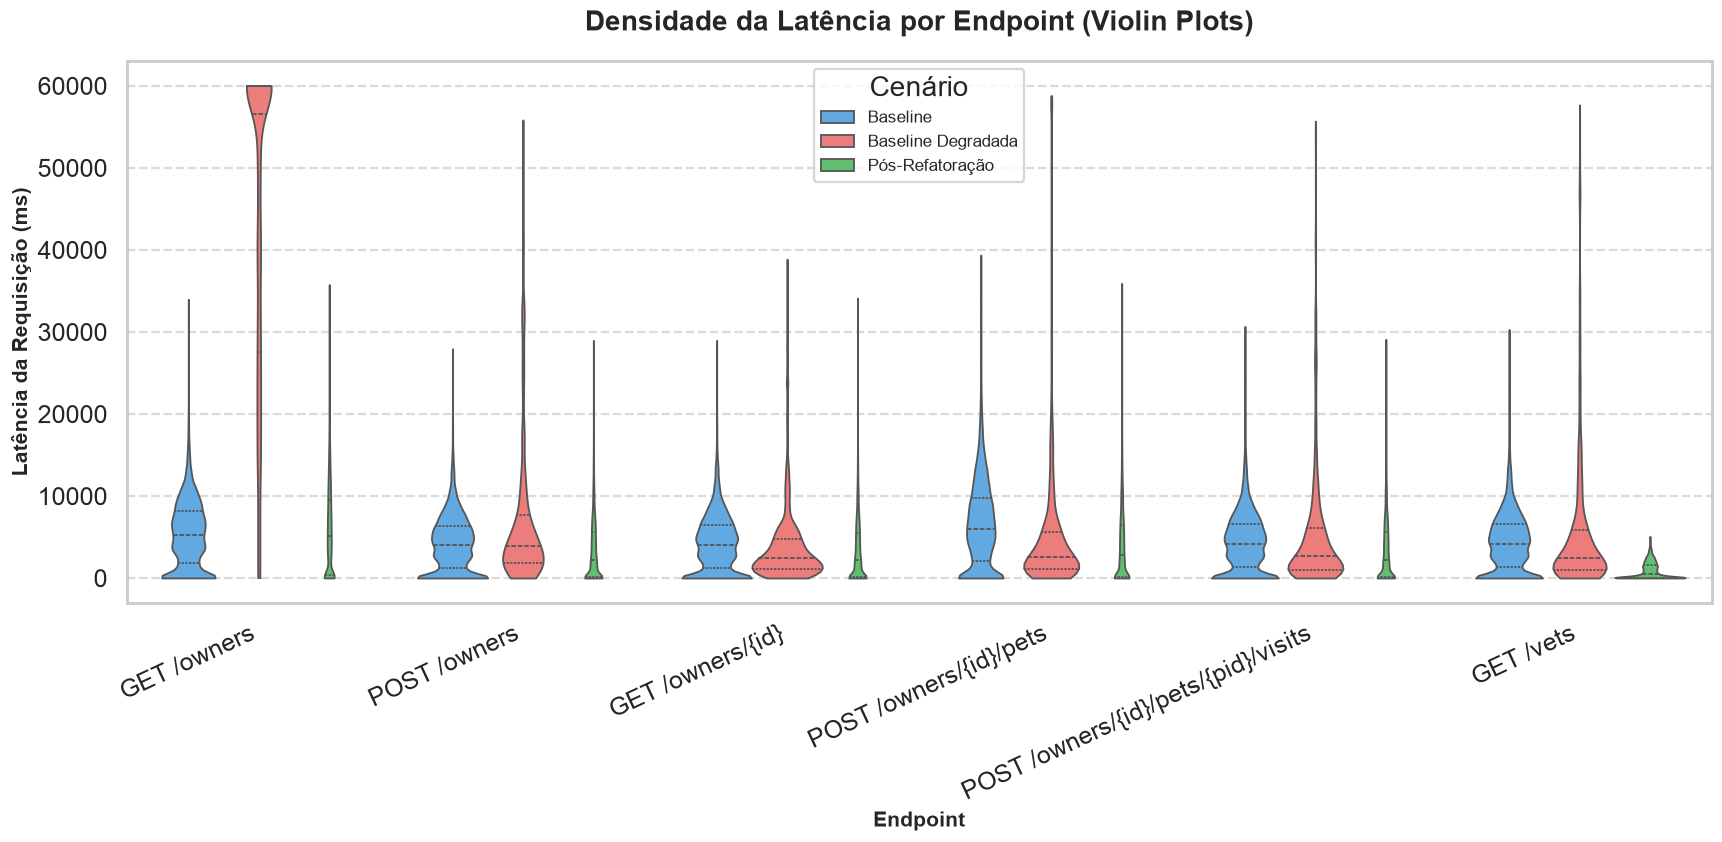

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 3 — Densidade de probabilidade da latência (ms) por endpoint e cenário. As linhas internas marcam os quartis (25%, 50%/mediana, 75%).</i></div>

In [11]:
def plotar_violinplots_latencia(df_plot: pd.DataFrame):
    plt.figure(figsize=(16, 8))
    sns.violinplot(
        data=df_plot, x="Endpoint", y="metric_value", hue="Cenário",
        palette=PALETA, inner="quartile", linewidth=1.2, cut=0,
    )
    plt.title("Densidade da Latência por Endpoint (Violin Plots)", fontsize=18, pad=20)
    plt.xlabel("Endpoint", fontsize=14, fontweight="bold")
    plt.ylabel("Latência da Requisição (ms)", fontsize=14, fontweight="bold")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(title="Cenário", fontsize=11)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figura_03_violinplot_latencia.png", dpi=300)
    plt.show()

plotar_violinplots_latencia(DF_LATENCIA)
legenda("Figura 3 — Densidade de probabilidade da latência (ms) por endpoint e cenário. As "
        "linhas internas marcam os quartis (25%, 50%/mediana, 75%).")

### 4.3 Throughput e Curva do Joelho (Séries Temporais)

Evolução da vazão e erros ao longo do tempo; identifica o ponto de saturação.


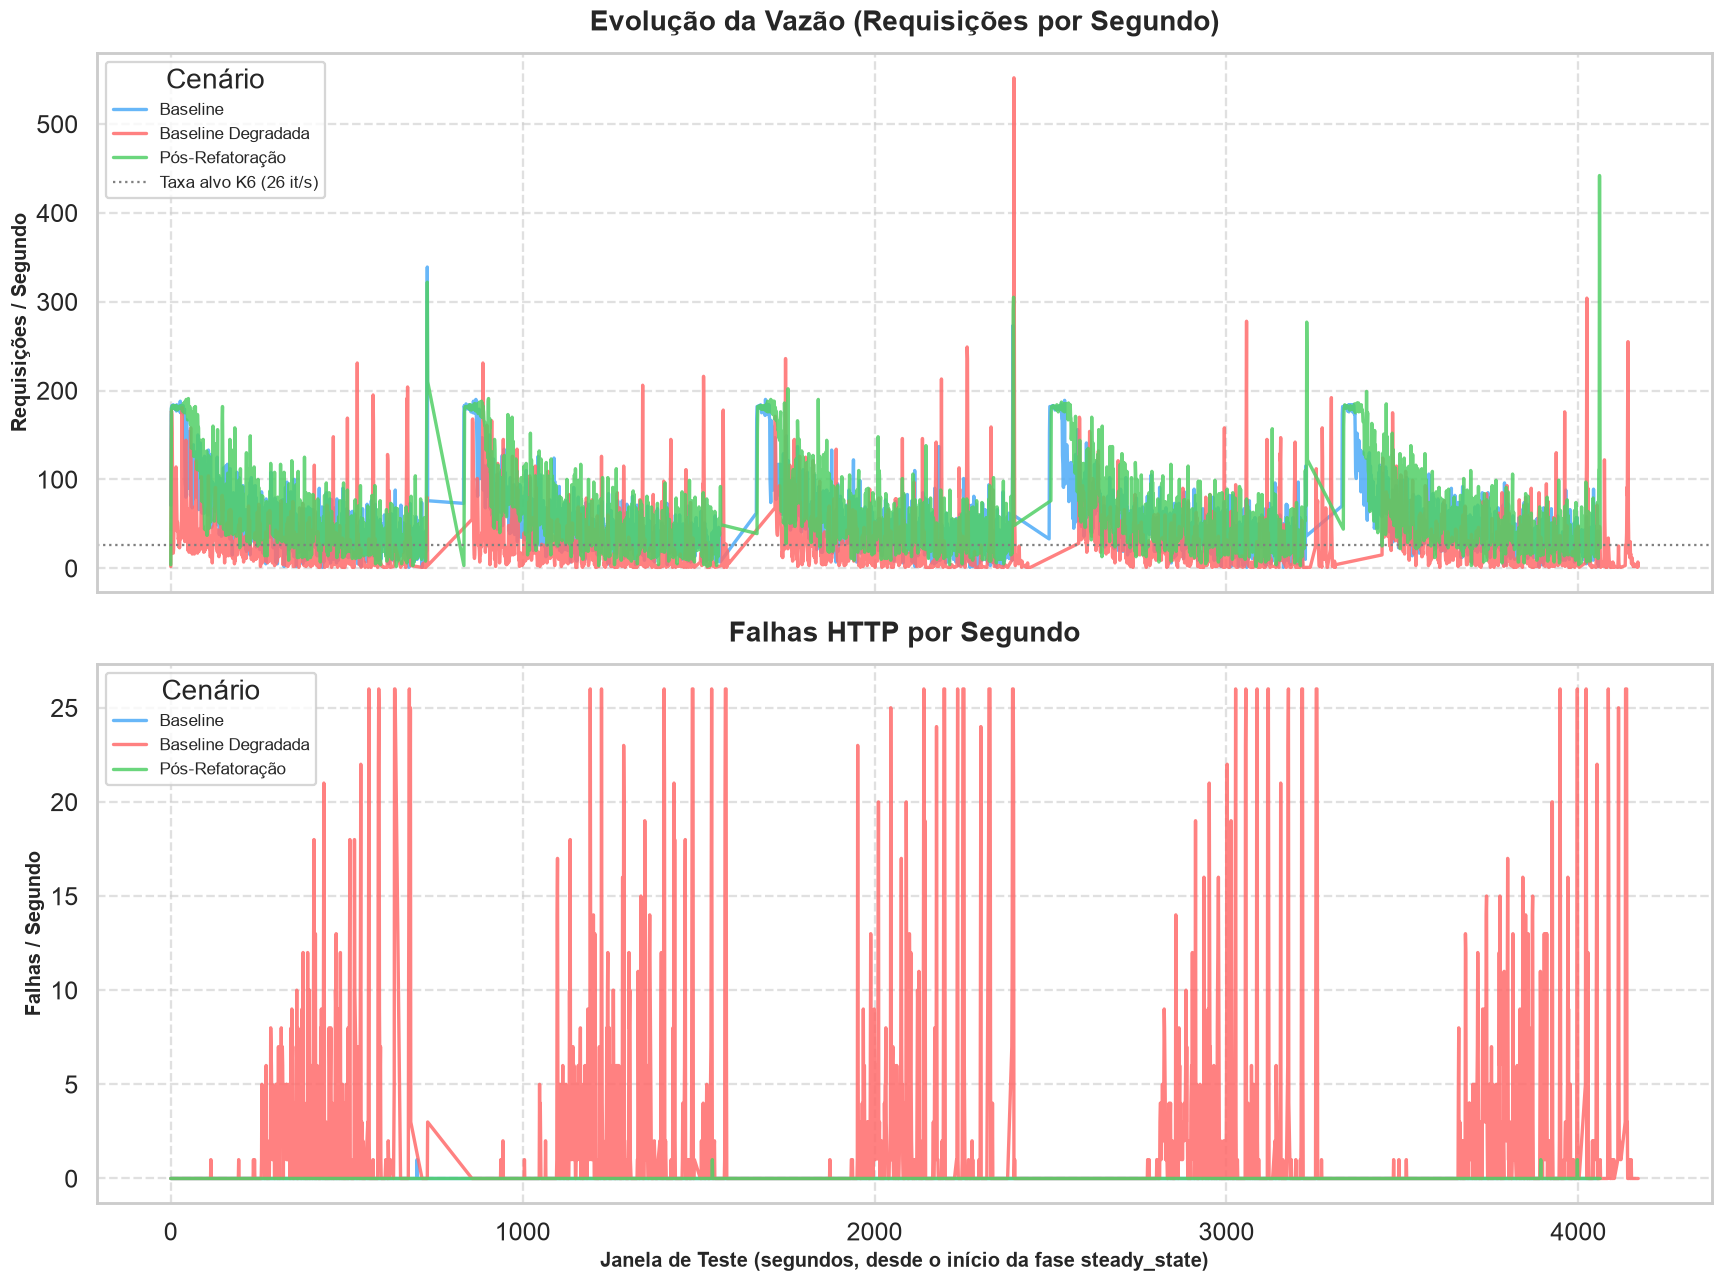

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 4 — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) ao longo da fase steady_state, por cenário. A linha pontilhada em 26 req/s marca a taxa alvo do executor constant-arrival-rate; quedas sustentadas abaixo dela, combinadas com dropped_iterations > 0 (Seção 3.1), evidenciam saturação real da branch.</i></div>

In [12]:
def plotar_series_temporais_joelho(dados_k6: dict):
    frames = []
    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue

        # RPS: 1 requisição por linha de http_req_duration, agrupada por segundo
        df_reqs = df[df["metric_name"] == "http_req_duration"].copy()
        df_reqs["datetime"] = pd.to_datetime(df_reqs["timestamp"], unit="s").dt.floor("s")
        rps = df_reqs.groupby("datetime").size().reset_index(name="RPS")

        # Erros: http_req_failed == 1 significa falha na requisição
        df_fails = df[df["metric_name"] == "http_req_failed"].copy()
        df_fails["datetime"] = pd.to_datetime(df_fails["timestamp"], unit="s").dt.floor("s")
        fails = (df_fails[df_fails["metric_value"] > 0]
                 .groupby("datetime").size().reset_index(name="Erros"))

        df_time = pd.merge(rps, fails, on="datetime", how="left").fillna(0)
        inicio = df_time["datetime"].min()
        df_time["Tempo de Teste (s)"] = (df_time["datetime"] - inicio).dt.total_seconds()
        df_time["Cenário"] = SCENARIOS[nome_cenario]["label"]
        frames.append(df_time)

    if not frames:
        print("Sem dados suficientes para gerar a série temporal.")
        return

    df_plot = pd.concat(frames, ignore_index=True)
    df_plot["Cenário"] = pd.Categorical(df_plot["Cenário"], categories=ORDEM_CENARIOS, ordered=True)

    fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

    sns.lineplot(data=df_plot, x="Tempo de Teste (s)", y="RPS", hue="Cenário",
                 palette=PALETA, ax=axes[0], linewidth=2.2, alpha=0.85)
    axes[0].set_title("Evolução da Vazão (Requisições por Segundo)", fontsize=18, pad=15)
    axes[0].set_ylabel("Requisições / Segundo", fontsize=13, fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].axhline(26, color="gray", linestyle=":", linewidth=1.5, label="Taxa alvo K6 (26 it/s)")

    sns.lineplot(data=df_plot, x="Tempo de Teste (s)", y="Erros", hue="Cenário",
                 palette=PALETA, ax=axes[1], linewidth=2.2, alpha=0.85)
    axes[1].set_title("Falhas HTTP por Segundo", fontsize=18, pad=15)
    axes[1].set_xlabel("Janela de Teste (segundos, desde o início da fase steady_state)", fontsize=13, fontweight="bold")
    axes[1].set_ylabel("Falhas / Segundo", fontsize=13, fontweight="bold")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    for ax in axes:
        ax.legend(title="Cenário", fontsize=11)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figura_04_serie_temporal_rps_erros.png", dpi=300)
    plt.show()

plotar_series_temporais_joelho(dados_k6)
legenda("Figura 4 — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) "
        "ao longo da fase steady_state, por cenário. A linha pontilhada em 26 req/s marca a "
        "taxa alvo do executor constant-arrival-rate; quedas sustentadas abaixo dela, "
        "combinadas com dropped_iterations > 0 (Seção 3.1), evidenciam saturação real da branch.")

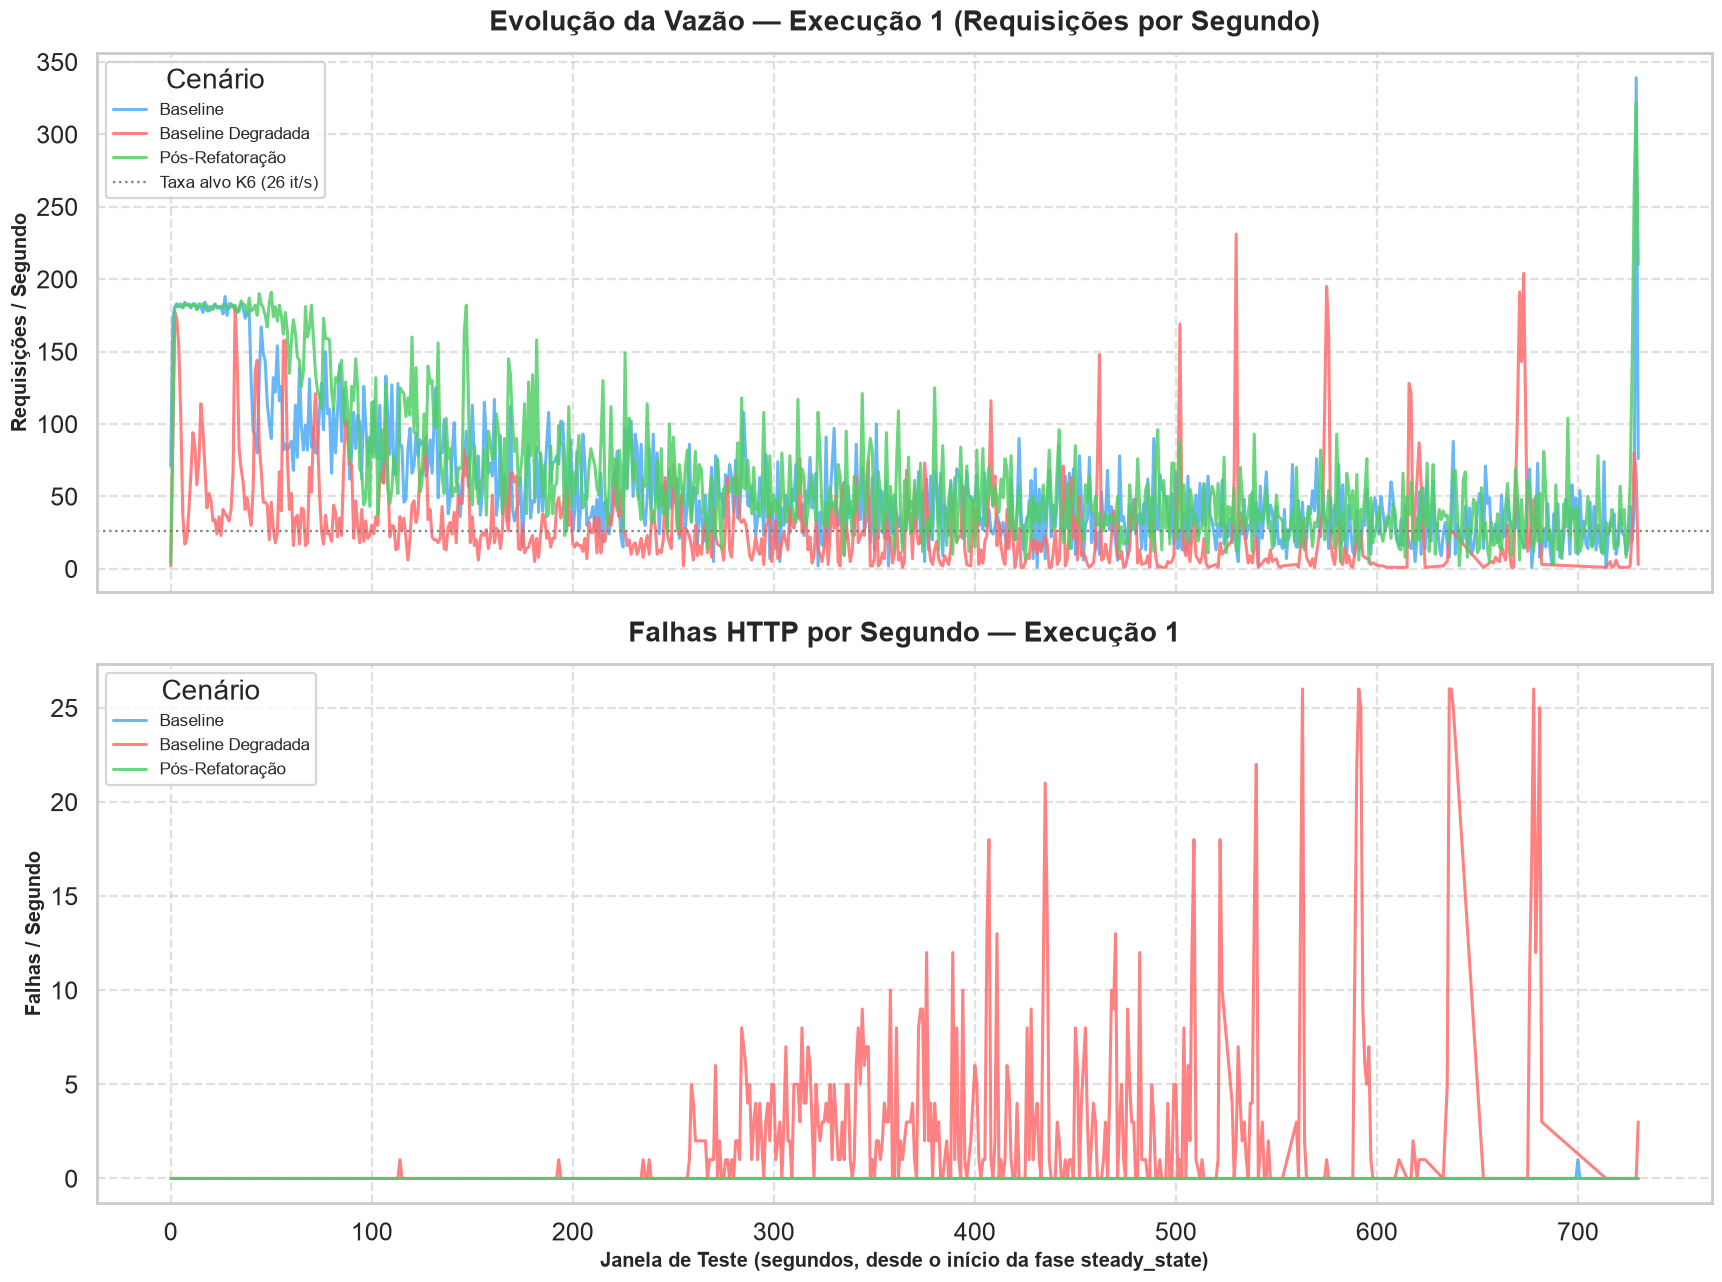

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 5 (Run 1) — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) na Execução 1, isolada por cenário. Comparação par a par entre as branches nesta mesma rodada, sem a sobreposição das demais execuções — útil para verificar se o padrão de saturação da Figura 4 é consistente rodada a rodada, ou concentrado em uma execução específica.</i></div>

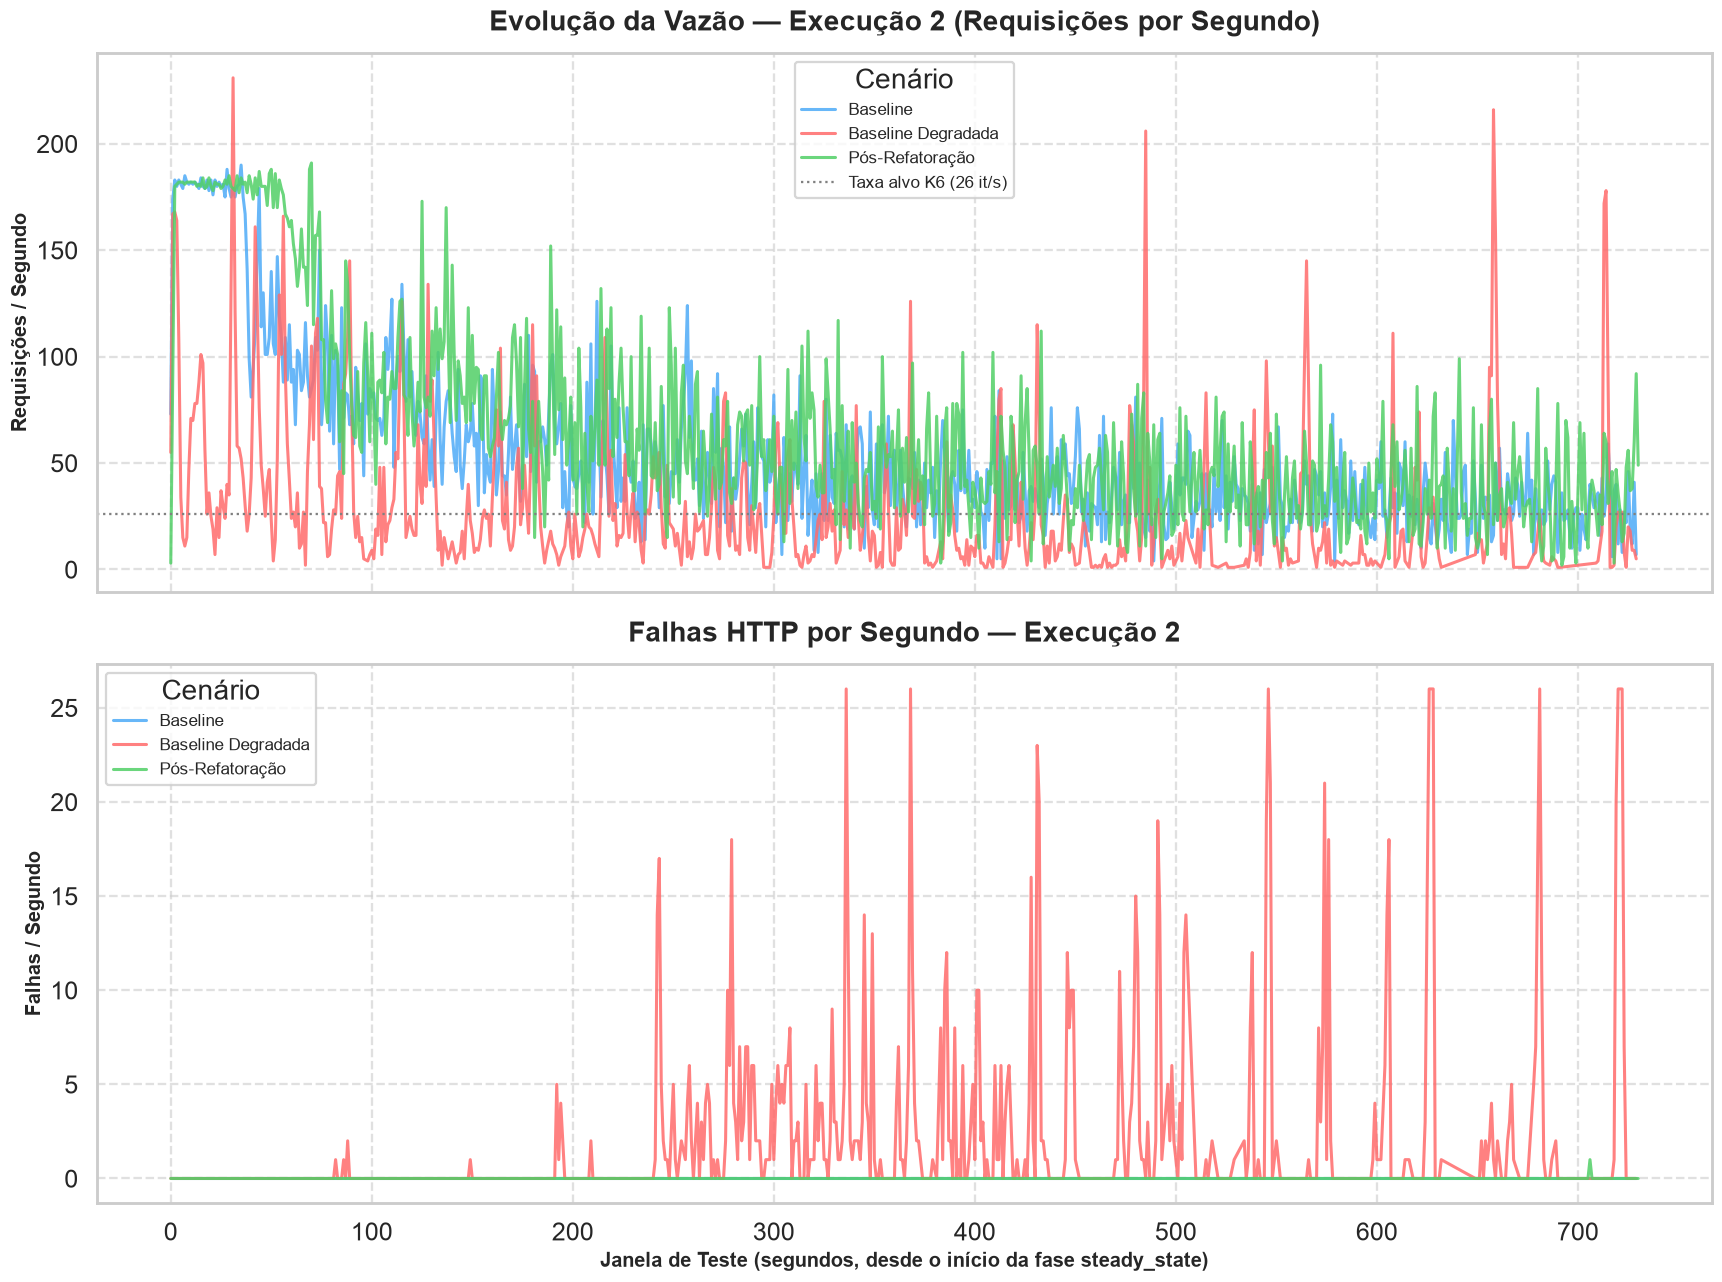

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 5 (Run 2) — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) na Execução 2, isolada por cenário. Comparação par a par entre as branches nesta mesma rodada, sem a sobreposição das demais execuções — útil para verificar se o padrão de saturação da Figura 4 é consistente rodada a rodada, ou concentrado em uma execução específica.</i></div>

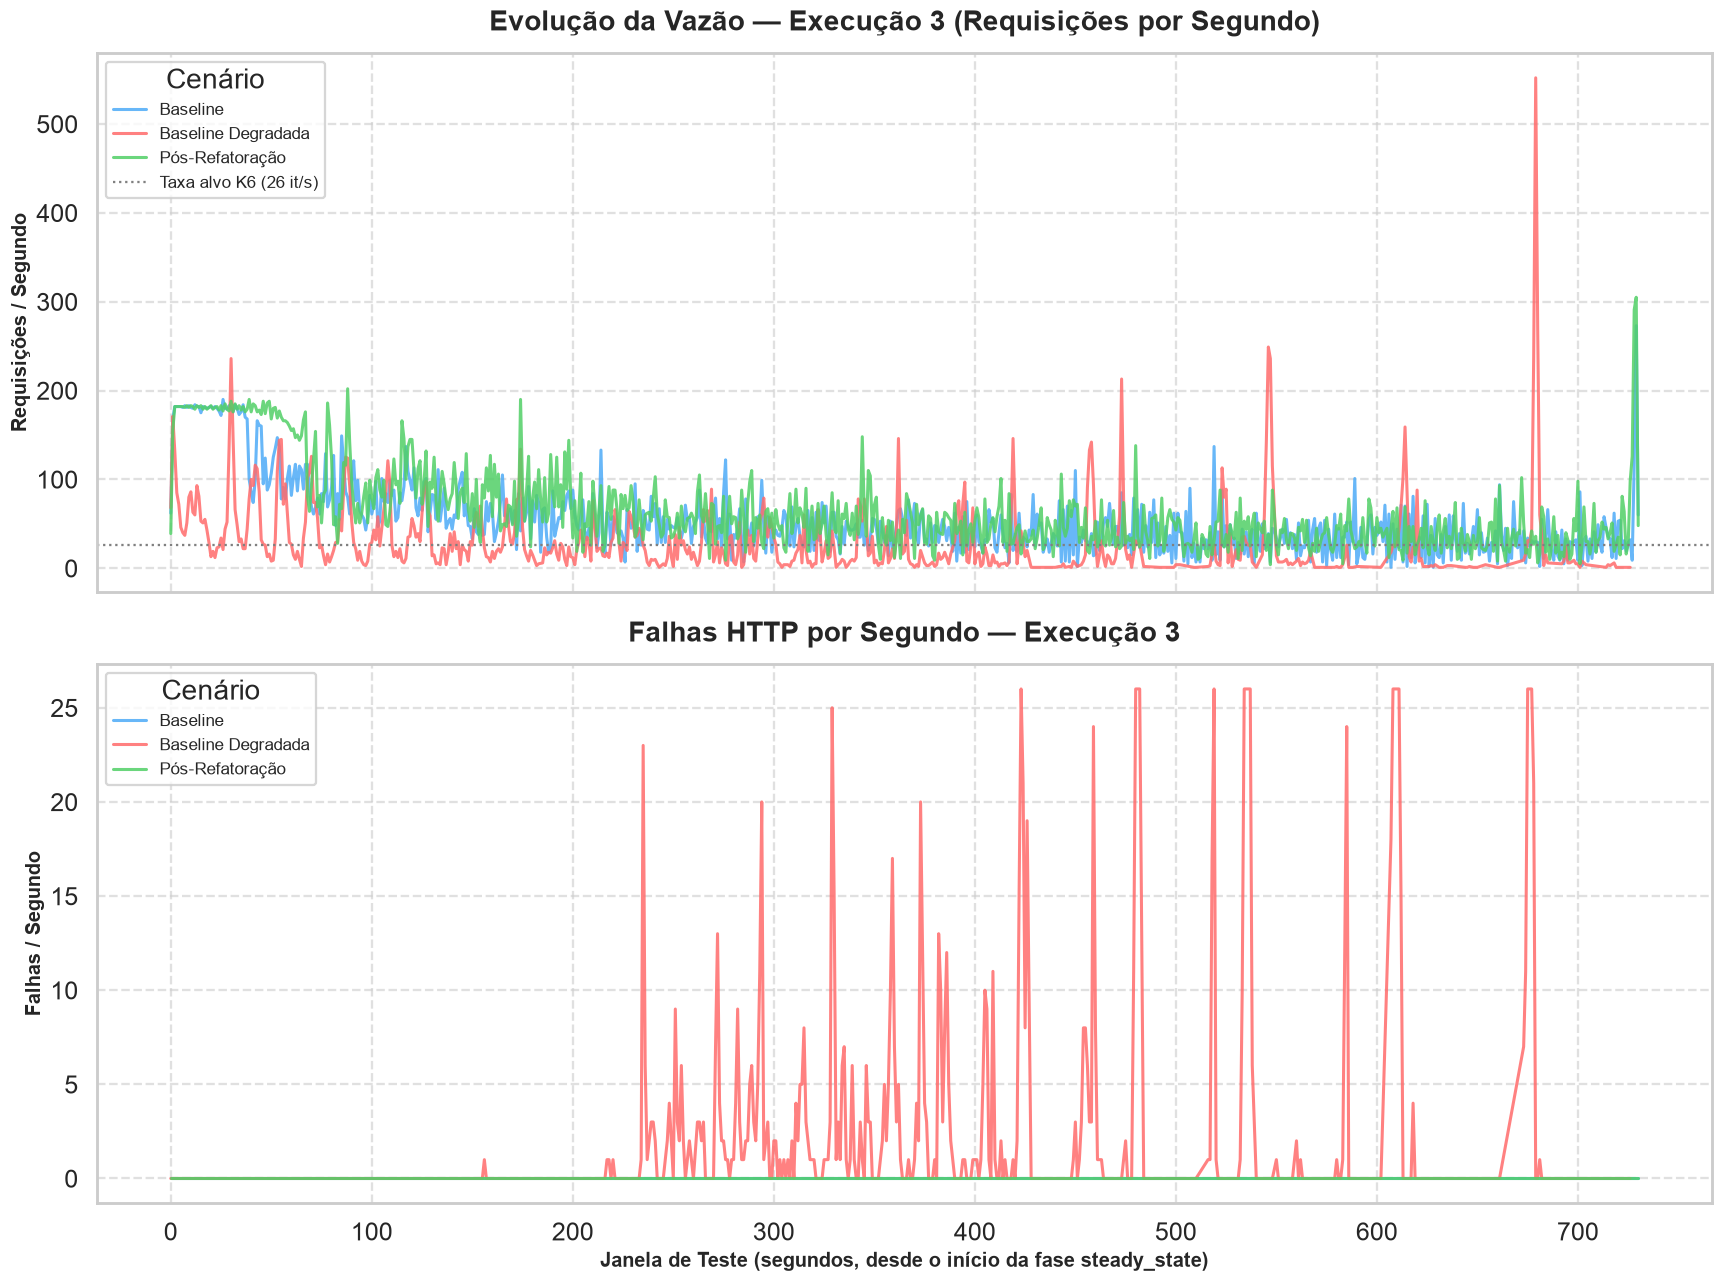

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 5 (Run 3) — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) na Execução 3, isolada por cenário. Comparação par a par entre as branches nesta mesma rodada, sem a sobreposição das demais execuções — útil para verificar se o padrão de saturação da Figura 4 é consistente rodada a rodada, ou concentrado em uma execução específica.</i></div>

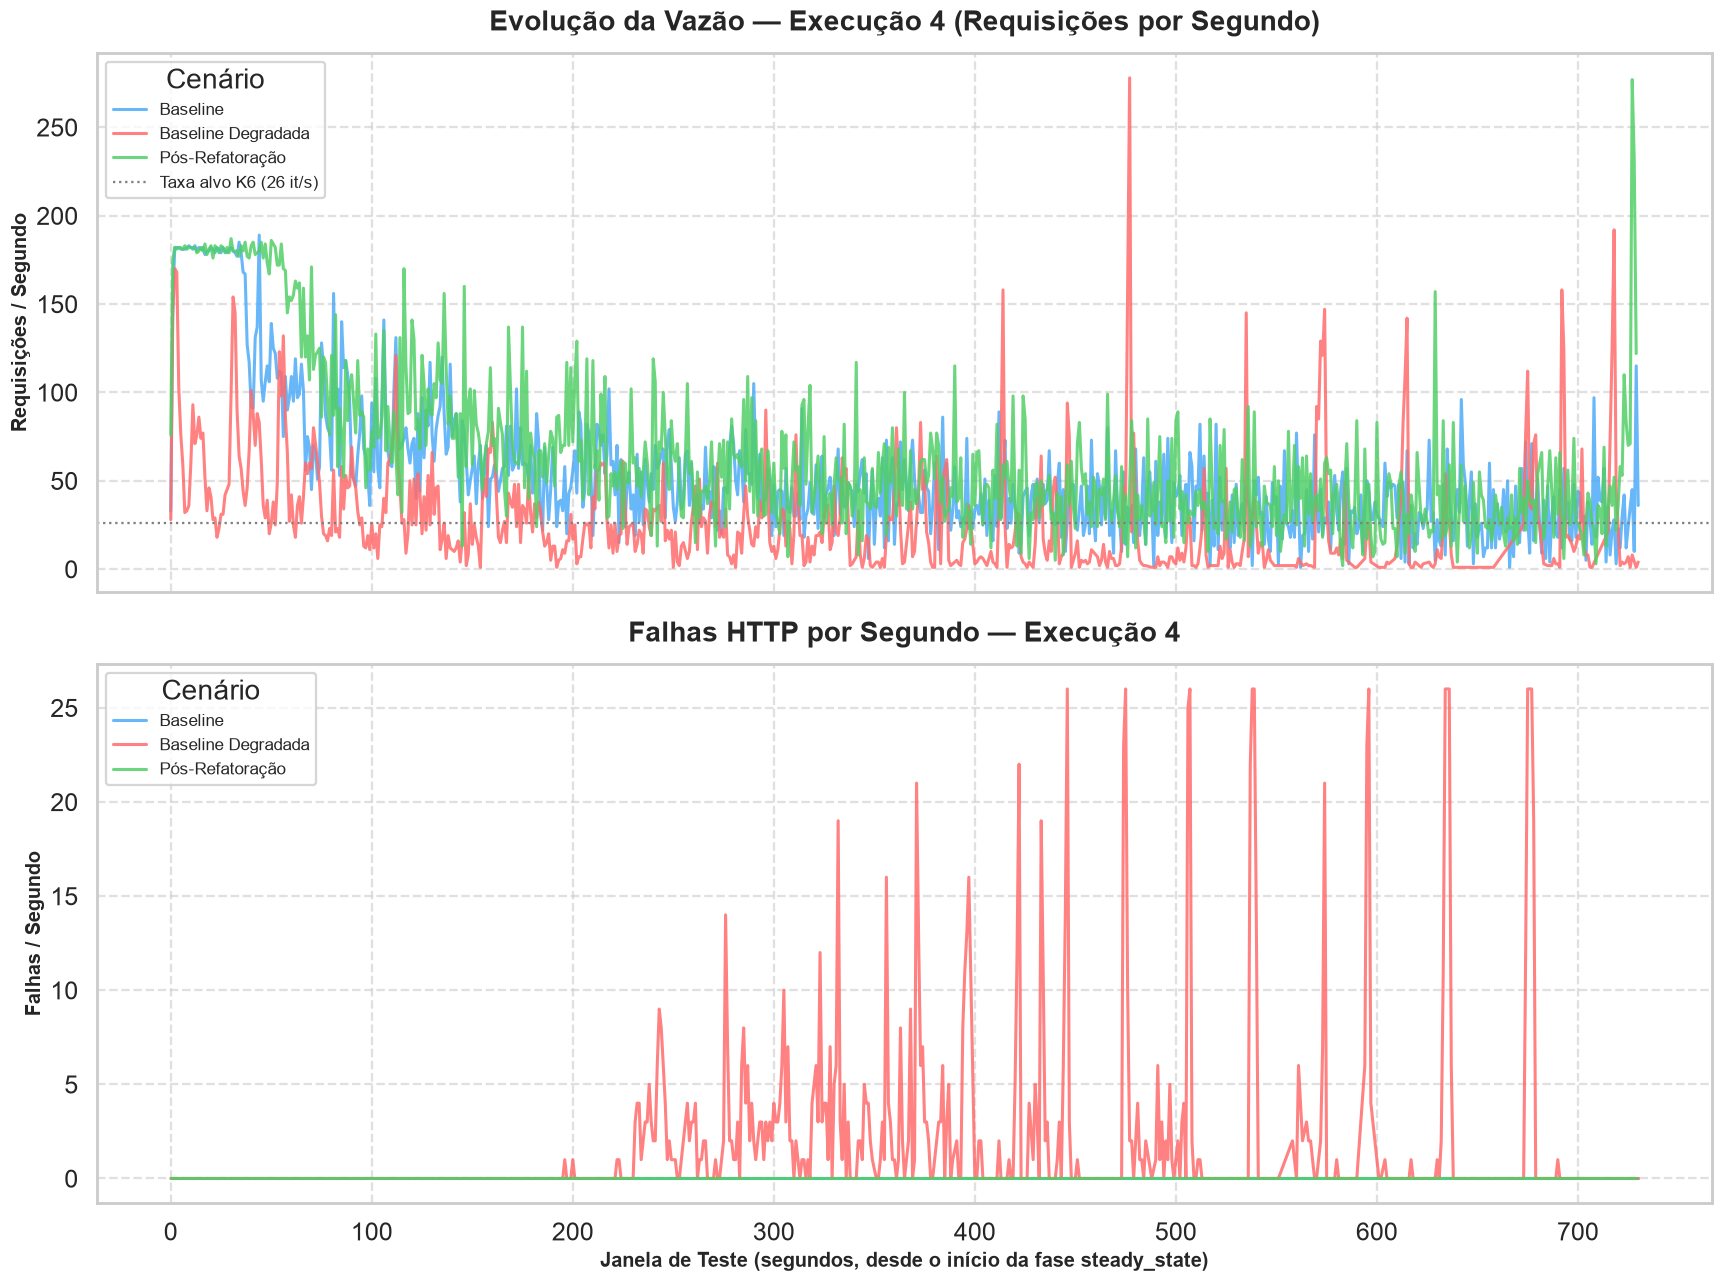

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 5 (Run 4) — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) na Execução 4, isolada por cenário. Comparação par a par entre as branches nesta mesma rodada, sem a sobreposição das demais execuções — útil para verificar se o padrão de saturação da Figura 4 é consistente rodada a rodada, ou concentrado em uma execução específica.</i></div>

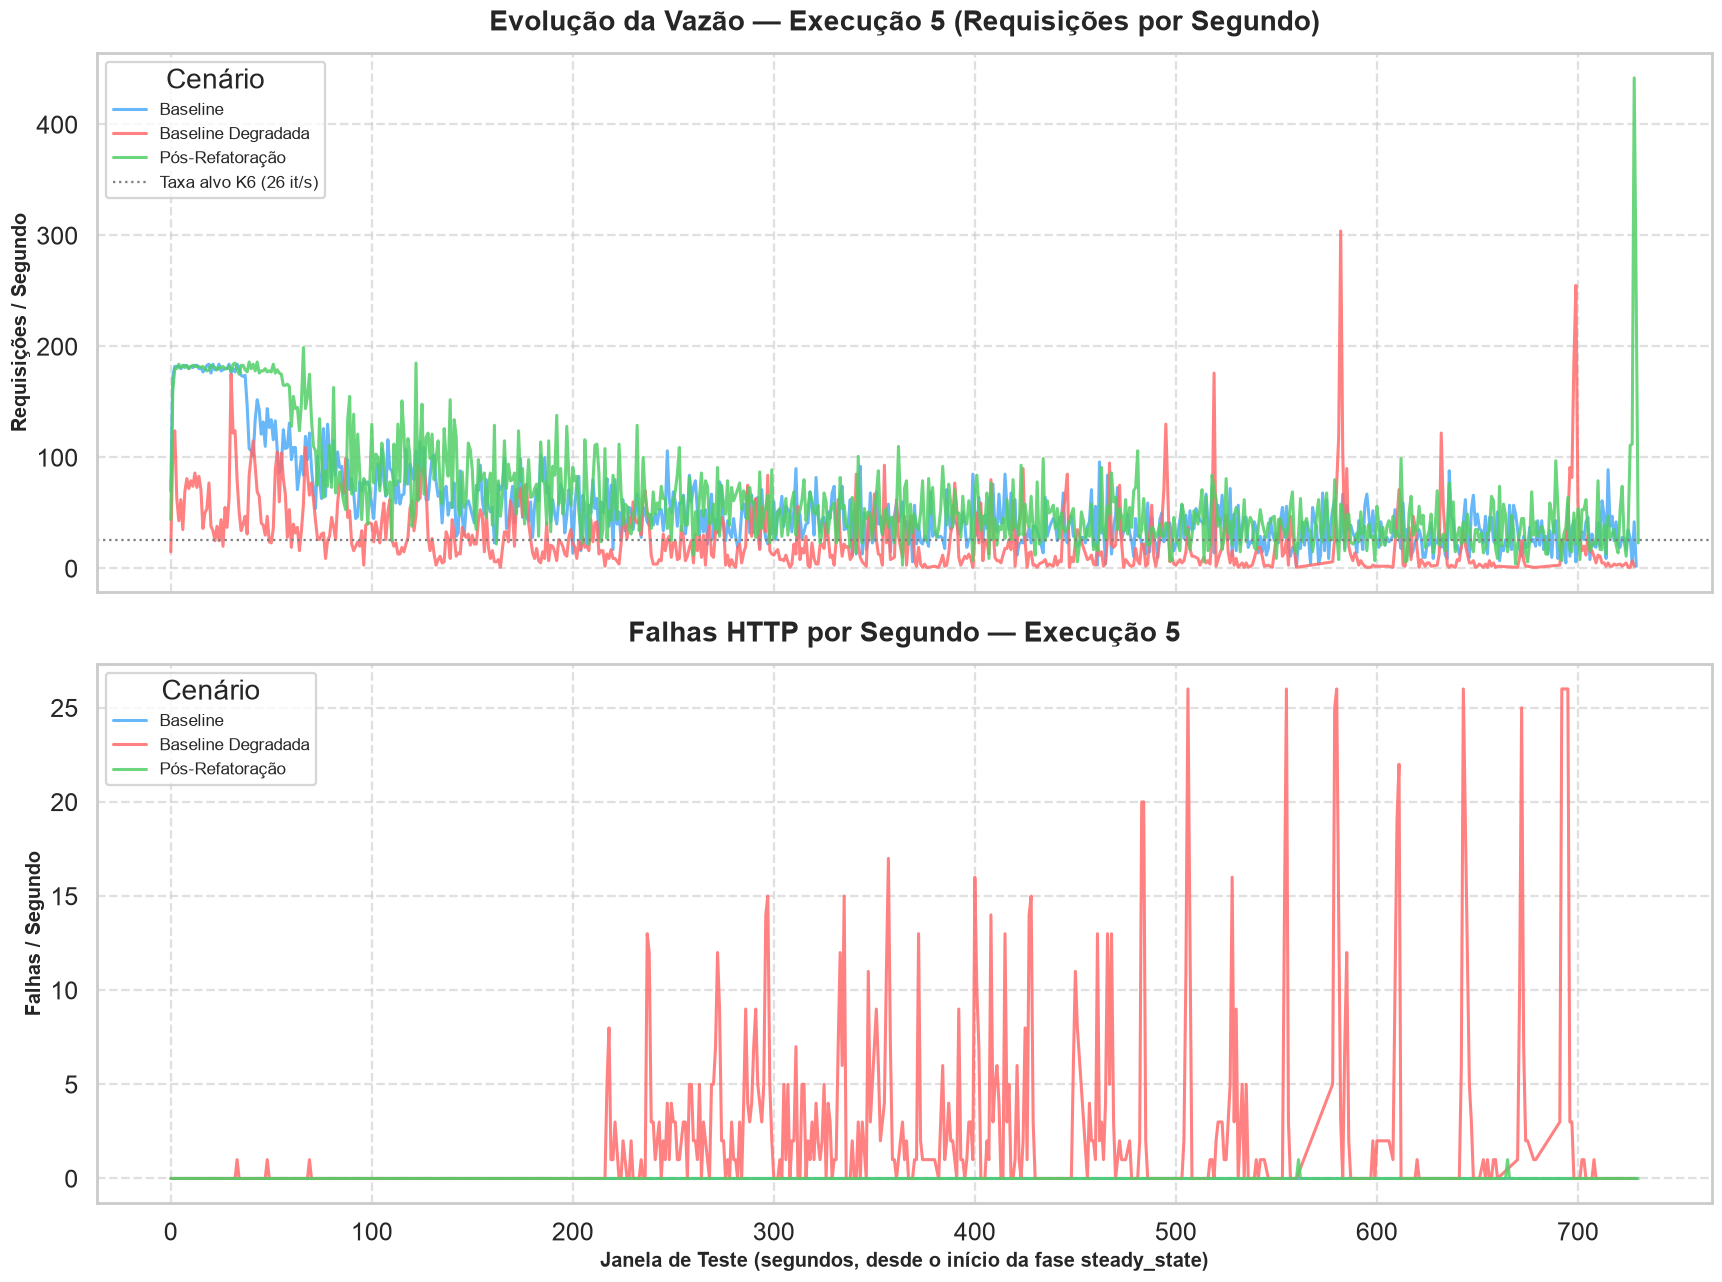

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 5 (Run 5) — Vazão (RPS, painel superior) e falhas HTTP por segundo (painel inferior) na Execução 5, isolada por cenário. Comparação par a par entre as branches nesta mesma rodada, sem a sobreposição das demais execuções — útil para verificar se o padrão de saturação da Figura 4 é consistente rodada a rodada, ou concentrado em uma execução específica.</i></div>

In [13]:
def plotar_series_temporais_joelho_por_execucao(dados_k6: dict):
    """Mesma lógica da Figura 4, mas isolando cada execução (run) em uma figura própria,
    para inspecionar se o padrão de saturação se repete rodada a rodada ou é dominado por
    uma execução específica (a sobreposição das 5 execuções na Fig. 4.3 pode mascarar isso)."""
    runs_disponiveis = sorted(set().union(
        *[set(df["run"].unique()) for df in dados_k6.values() if not df.empty]
    ))

    for run_n in runs_disponiveis:
        frames = []
        for nome_cenario, df in dados_k6.items():
            df_run = df[df["run"] == run_n]
            if df_run.empty:
                continue

            df_reqs = df_run[df_run["metric_name"] == "http_req_duration"].copy()
            df_reqs["datetime"] = pd.to_datetime(df_reqs["timestamp"], unit="s").dt.floor("s")
            rps = df_reqs.groupby("datetime").size().reset_index(name="RPS")

            df_fails = df_run[df_run["metric_name"] == "http_req_failed"].copy()
            df_fails["datetime"] = pd.to_datetime(df_fails["timestamp"], unit="s").dt.floor("s")
            fails = (df_fails[df_fails["metric_value"] > 0]
                     .groupby("datetime").size().reset_index(name="Erros"))

            df_time = pd.merge(rps, fails, on="datetime", how="left").fillna(0)
            inicio = df_time["datetime"].min()
            df_time["Tempo de Teste (s)"] = (df_time["datetime"] - inicio).dt.total_seconds()
            df_time["Cenário"] = SCENARIOS[nome_cenario]["label"]
            frames.append(df_time)

        if not frames:
            continue

        df_plot = pd.concat(frames, ignore_index=True)
        df_plot["Cenário"] = pd.Categorical(df_plot["Cenário"], categories=ORDEM_CENARIOS, ordered=True)

        fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

        sns.lineplot(data=df_plot, x="Tempo de Teste (s)", y="RPS", hue="Cenário",
                     palette=PALETA, ax=axes[0], linewidth=2.0, alpha=0.85)
        axes[0].set_title(f"Evolução da Vazão — Execução {run_n} (Requisições por Segundo)",
                           fontsize=18, pad=15)
        axes[0].set_ylabel("Requisições / Segundo", fontsize=13, fontweight="bold")
        axes[0].grid(True, linestyle="--", alpha=0.6)
        axes[0].axhline(26, color="gray", linestyle=":", linewidth=1.5, label="Taxa alvo K6 (26 it/s)")

        sns.lineplot(data=df_plot, x="Tempo de Teste (s)", y="Erros", hue="Cenário",
                     palette=PALETA, ax=axes[1], linewidth=2.0, alpha=0.85)
        axes[1].set_title(f"Falhas HTTP por Segundo — Execução {run_n}", fontsize=18, pad=15)
        axes[1].set_xlabel("Janela de Teste (segundos, desde o início da fase steady_state)",
                            fontsize=13, fontweight="bold")
        axes[1].set_ylabel("Falhas / Segundo", fontsize=13, fontweight="bold")
        axes[1].grid(True, linestyle="--", alpha=0.6)

        for ax in axes:
            ax.legend(title="Cenário", fontsize=11)

        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / f"figura_05_serie_temporal_rps_erros_run{run_n}.png", dpi=300)
        plt.show()

        legenda(f"Figura 5 (Run {run_n}) — Vazão (RPS, painel superior) e falhas HTTP por segundo "
                f"(painel inferior) na Execução {run_n}, isolada por cenário. Comparação par a "
                f"par entre as branches nesta mesma rodada, sem a sobreposição das demais "
                f"execuções — útil para verificar se o padrão de saturação da Figura 4 é "
                f"consistente rodada a rodada, ou concentrado em uma execução específica.")


plotar_series_temporais_joelho_por_execucao(dados_k6)

### 4.3.1 Latência ao Longo do Tempo

Latência média e p95 agregadas em janelas de tempo por cenário.


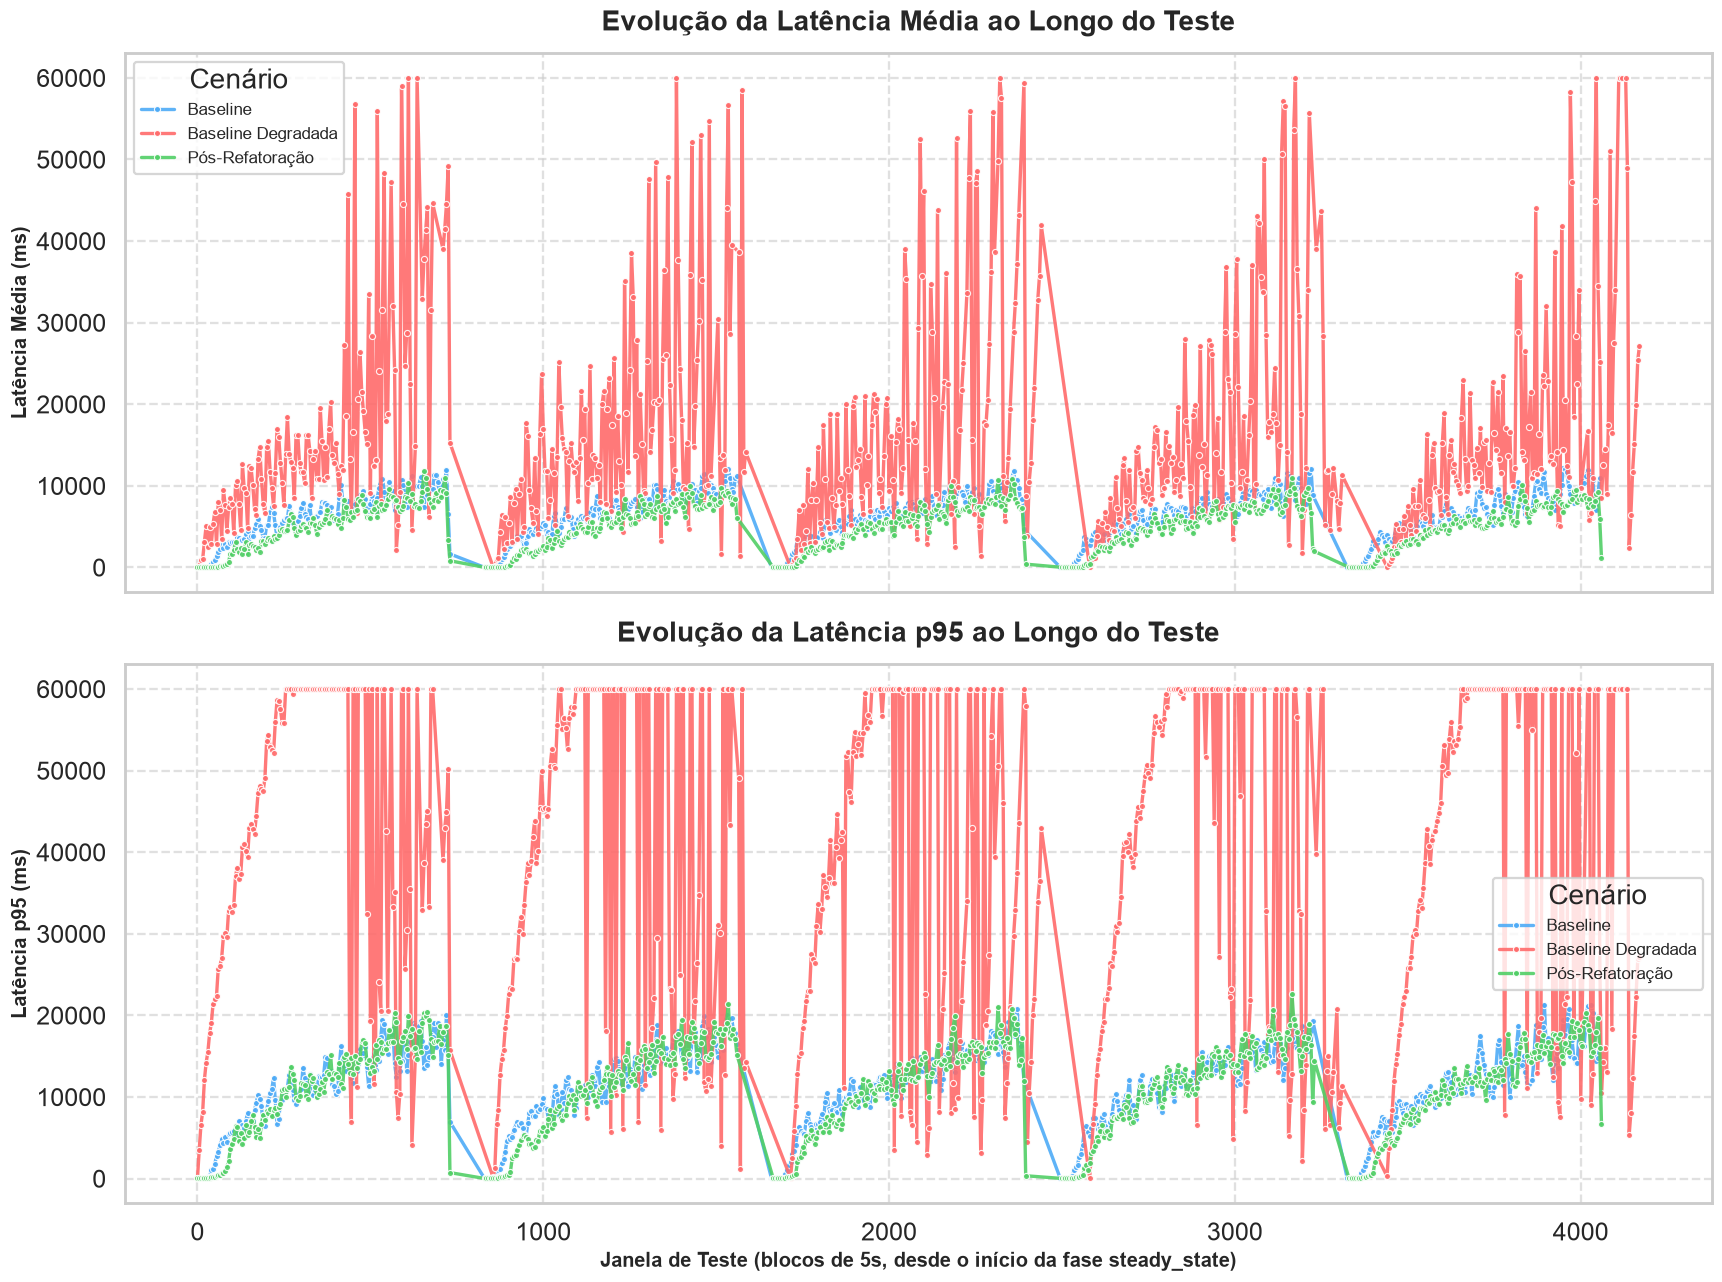

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 6 — Latência média (painel superior) e p95 (painel inferior), agregadas em janelas de 5 segundos, ao longo da fase steady_state, por cenário. A linha da versão Pós-Refatoração tende a permanecer baixa e estável; oscilações e crescimento sustentado na linha da Baseline Degradada tangibilizam o colapso sob carga descrito na Tabela 8, complementando a leitura de vazão da Figura 4</i></div>

In [14]:
def plotar_serie_temporal_latencia(dados_k6: dict, janela_s: int = 5):
    """Latência média (ms) e p95 (ms) agregadas em janelas de `janela_s` segundos,
    por cenário, ao longo da fase steady_state. Complementa a Figura 4 (RPS/erros)
    com o eixo de latência explicitamente pedido para tangibilizar o colapso sob carga."""
    frames = []
    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue

        df_lat = df[df["metric_name"] == "http_req_duration"].copy()
        if df_lat.empty:
            continue

        df_lat["datetime"] = pd.to_datetime(df_lat["timestamp"], unit="s")
        inicio = df_lat["datetime"].min()
        df_lat["Tempo de Teste (s)"] = (df_lat["datetime"] - inicio).dt.total_seconds()
        df_lat["Janela (s)"] = (df_lat["Tempo de Teste (s)"] // janela_s) * janela_s

        agregado = (df_lat.groupby("Janela (s)")["metric_value"]
                    .agg(media="mean", p95=lambda x: x.quantile(0.95))
                    .reset_index())
        agregado["Cenário"] = SCENARIOS[nome_cenario]["label"]
        frames.append(agregado)

    if not frames:
        print("Sem dados suficientes para gerar a série temporal de latência.")
        return

    df_plot = pd.concat(frames, ignore_index=True)
    df_plot["Cenário"] = pd.Categorical(df_plot["Cenário"], categories=ORDEM_CENARIOS, ordered=True)

    fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

    sns.lineplot(data=df_plot, x="Janela (s)", y="media", hue="Cenário",
                 palette=PALETA, ax=axes[0], linewidth=2.2, marker="o", markersize=4, alpha=0.9)
    axes[0].set_title("Evolução da Latência Média ao Longo do Teste", fontsize=18, pad=15)
    axes[0].set_ylabel("Latência Média (ms)", fontsize=13, fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.6)

    sns.lineplot(data=df_plot, x="Janela (s)", y="p95", hue="Cenário",
                 palette=PALETA, ax=axes[1], linewidth=2.2, marker="o", markersize=4, alpha=0.9)
    axes[1].set_title("Evolução da Latência p95 ao Longo do Teste", fontsize=18, pad=15)
    axes[1].set_xlabel(f"Janela de Teste (blocos de {janela_s}s, desde o início da fase steady_state)",
                        fontsize=13, fontweight="bold")
    axes[1].set_ylabel("Latência p95 (ms)", fontsize=13, fontweight="bold")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    for ax in axes:
        ax.legend(title="Cenário", fontsize=11)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figura_06_serie_temporal_latencia_global.png", dpi=300)
    plt.show()


plotar_serie_temporal_latencia(dados_k6)
legenda("Figura 6 — Latência média (painel superior) e p95 (painel inferior), agregadas em "
        "janelas de 5 segundos, ao longo da fase steady_state, por cenário. A linha da versão "
        "Pós-Refatoração tende a permanecer baixa e estável; oscilações e crescimento sustentado "
        "na linha da Baseline Degradada tangibilizam o colapso sob carga descrito na Tabela 8, "
        "complementando a leitura de vazão da Figura 4")

### 4.3.2 Latência por Endpoint Específico

Detalha o colapso individual de latência para o endpoint `GET /owners`.


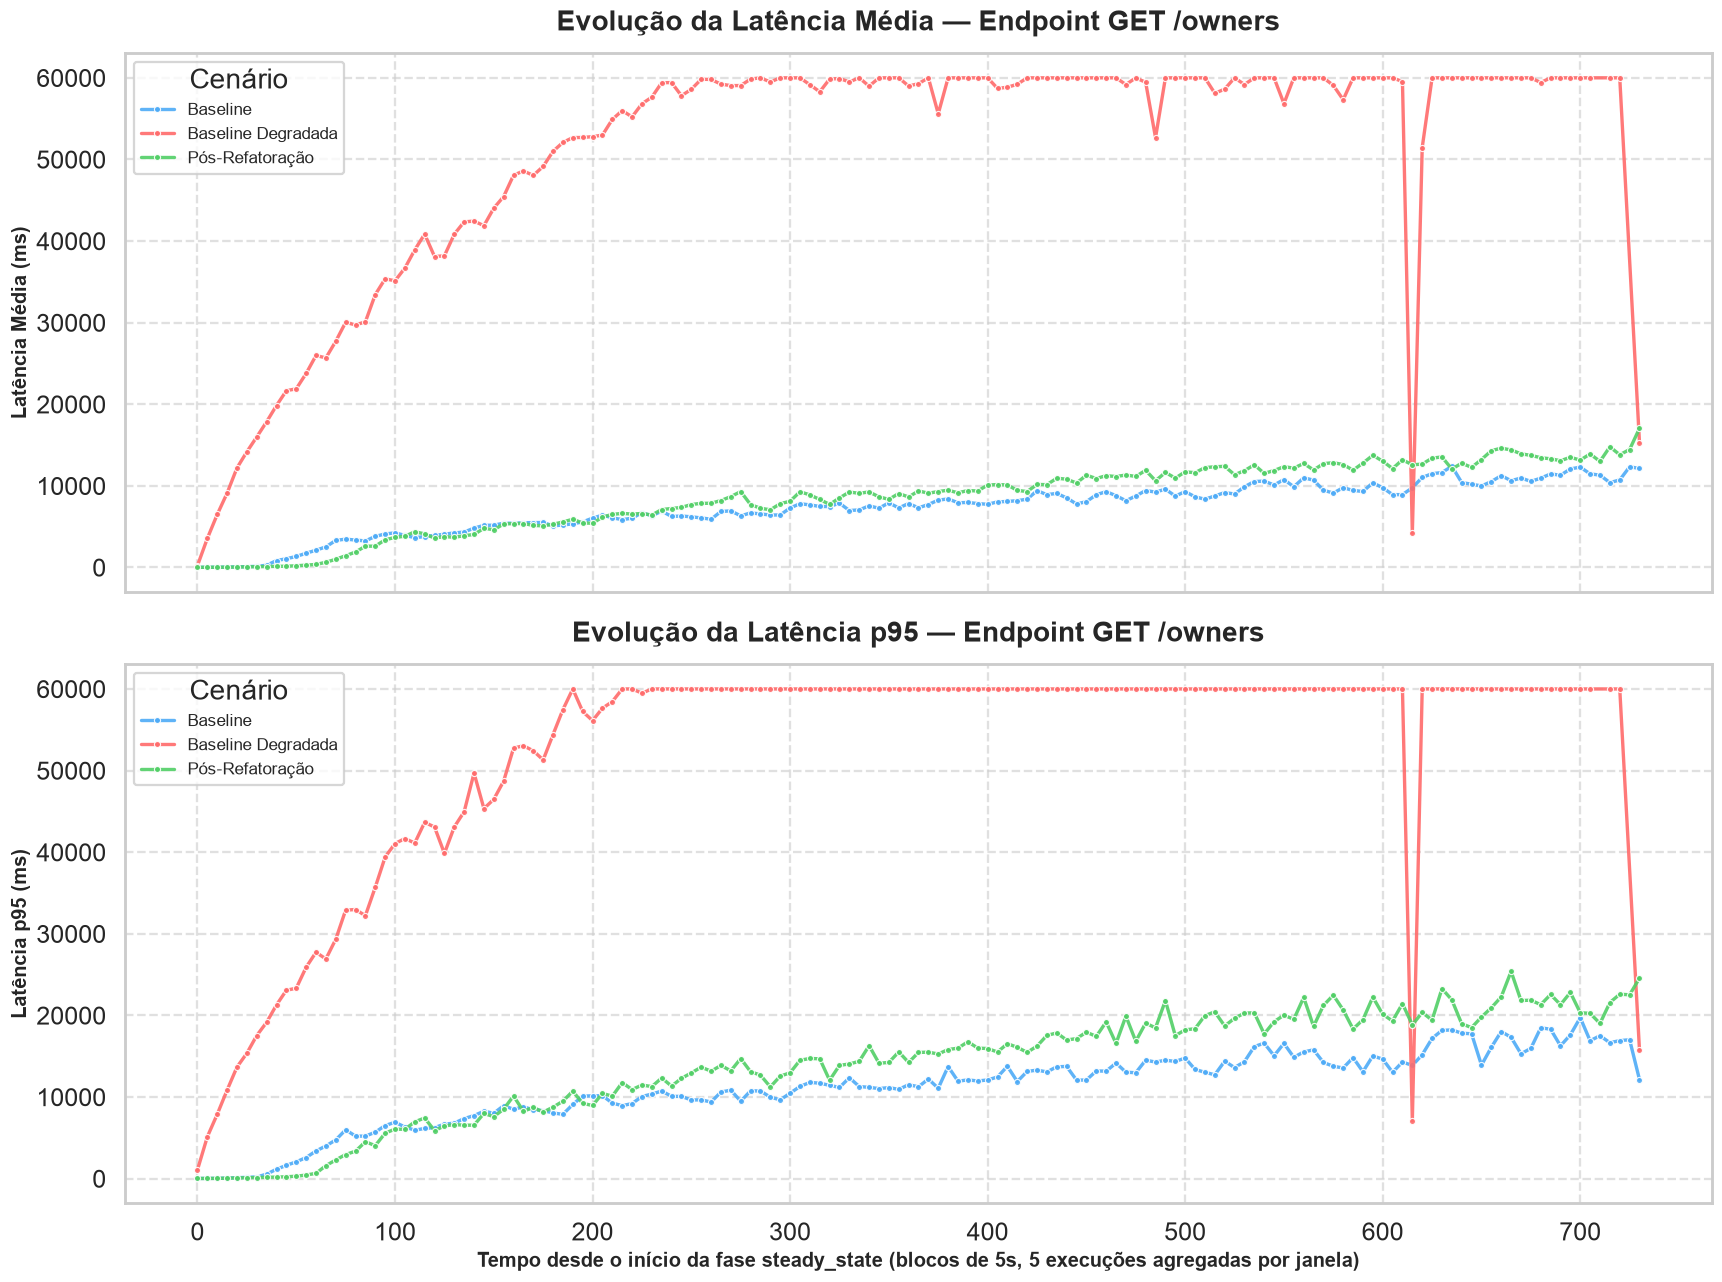

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 7 — Latência média (painel superior) e p95 (painel inferior) do endpoint GET /owners, agregadas em janelas de 5s desde o início da fase steady_state e combinando as 5 execuções de cada cenário (eixo X = tempo decorrido, não timestamp absoluto). A linha da versão Pós-Refatoração tende a permanecer baixa e estável; crescimento sustentado na linha da Baseline Degradada evidencia o colapso sob carga.</i></div>

In [15]:
def plotar_serie_temporal_latencia_por_endpoint(dados_k6: dict, endpoint_alvo: str = "::GET /owners", janela_s: int = 5):
    """Latência média (ms) e p95 (ms) do endpoint `endpoint_alvo`, agregadas em janelas de
    `janela_s` segundos e agregadas também entre as 5 execuções (runs) de cada cenário, ao
    longo da fase steady_state. Eixo X = segundos decorridos desde o início do steady_state
    de cada execução (as 5 rodadas são sobrepostas na mesma origem t=0 e agregadas por janela).
    Endpoint padrão: GET /owners — o gargalo mais citado nas Seções 6/7 deste notebook."""
    rotulo_endpoint = ENDPOINTS_VALIDOS.get(endpoint_alvo, endpoint_alvo)
    frames = []
    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue

        df_lat = df[(df["metric_name"] == "http_req_duration") &
                    (df["group"] == endpoint_alvo)].copy()
        if df_lat.empty:
            continue

        # Tempo decorrido desde o início do steady_state, calculado por execução (run)
        # individualmente, para que as 5 rodadas comecem alinhadas em t=0 antes de agregar.
        df_lat["datetime"] = pd.to_datetime(df_lat["timestamp"], unit="s")
        df_lat["Tempo de Teste (s)"] = df_lat.groupby("run")["datetime"].transform(
            lambda s: (s - s.min()).dt.total_seconds()
        )
        df_lat["Janela (s)"] = (df_lat["Tempo de Teste (s)"] // janela_s) * janela_s

        agregado = (df_lat.groupby("Janela (s)")["metric_value"]
                    .agg(media="mean", p95=lambda x: x.quantile(0.95))
                    .reset_index())
        agregado["Cenário"] = SCENARIOS[nome_cenario]["label"]
        frames.append(agregado)

    if not frames:
        print(f"Sem dados suficientes para {rotulo_endpoint}.")
        return

    df_plot = pd.concat(frames, ignore_index=True)
    df_plot["Cenário"] = pd.Categorical(df_plot["Cenário"], categories=ORDEM_CENARIOS, ordered=True)

    fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

    sns.lineplot(data=df_plot, x="Janela (s)", y="media", hue="Cenário",
                 palette=PALETA, ax=axes[0], linewidth=2.2, marker="o", markersize=4, alpha=0.9)
    axes[0].set_title(f"Evolução da Latência Média — Endpoint {rotulo_endpoint}", fontsize=18, pad=15)
    axes[0].set_ylabel("Latência Média (ms)", fontsize=13, fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.6)

    sns.lineplot(data=df_plot, x="Janela (s)", y="p95", hue="Cenário",
                 palette=PALETA, ax=axes[1], linewidth=2.2, marker="o", markersize=4, alpha=0.9)
    axes[1].set_title(f"Evolução da Latência p95 — Endpoint {rotulo_endpoint}", fontsize=18, pad=15)
    axes[1].set_xlabel(f"Tempo desde o início da fase steady_state (blocos de {janela_s}s, "
                        f"5 execuções agregadas por janela)", fontsize=13, fontweight="bold")
    axes[1].set_ylabel("Latência p95 (ms)", fontsize=13, fontweight="bold")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    for ax in axes:
        ax.legend(title="Cenário", fontsize=11)

    plt.tight_layout()
    nome_arquivo = endpoint_alvo.replace("::", "").replace("/", "_").replace(" ", "_").replace("{", "").replace("}", "")
    plt.savefig(OUTPUT_DIR / f"figura_07_serie_temporal_latencia_{nome_arquivo}.png", dpi=300)
    plt.show()


plotar_serie_temporal_latencia_por_endpoint(dados_k6, endpoint_alvo="::GET /owners")
legenda(f"Figura 7 — Latência média (painel superior) e p95 (painel inferior) do endpoint "
        f"GET /owners, agregadas em janelas de 5s desde o início da fase steady_state e "
        f"combinando as 5 execuções de cada cenário (eixo X = tempo decorrido, não timestamp "
        f"absoluto). A linha da versão Pós-Refatoração tende a permanecer baixa e estável; "
        f"crescimento sustentado na linha da Baseline Degradada evidencia o colapso sob carga.")

#### Duração da fase steady_state por execução — Endpoint `::GET /owners`

,Baseline,Baseline Degradada,Pós-Refatoração
Run,,,
1,730.0,730.0,730.0
2,729.0,723.0,730.0
3,729.0,681.0,730.0
4,729.0,690.0,729.0
5,729.0,708.0,730.0
Mínimo comum,729.0,681.0,729.0


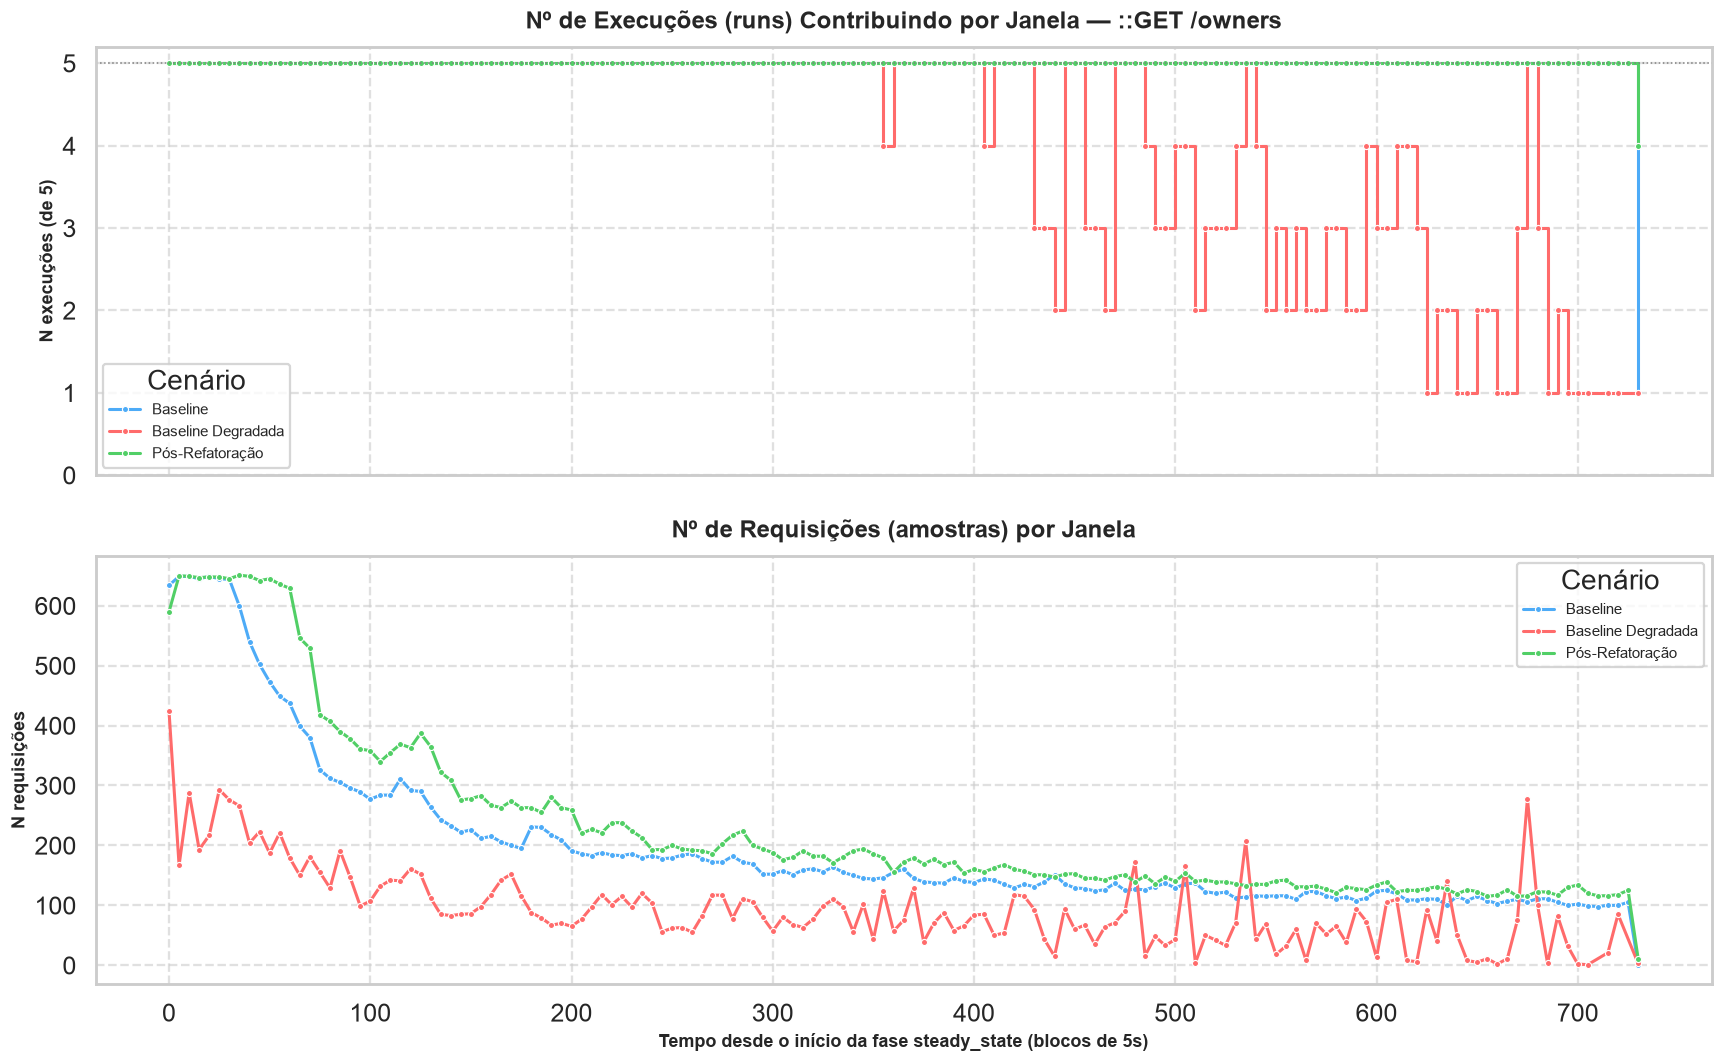

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 8 — Diagnóstico de cobertura de amostras por janela de tempo no endpoint GET /owners: painel superior mostra quantas execuções (runs, de um total de 5) contribuem em cada janela de 5s; painel inferior mostra o total de requisições amostradas. Quedas ao final da série com n_runs < 5 indicam bordas de teste (rampdown) e não devem ser interpretadas como degradação real de latência.</i></div>

In [16]:
# --- Célula: Diagnóstico de N por janela + versão truncada da série de latência ---

def diagnosticar_n_por_janela(dados_k6: dict, endpoint_alvo: str = "::GET /owners", janela_s: int = 5):
    """Para cada cenário, mostra quantas execuções (runs) e quantas requisições
    contribuem em cada janela de tempo — para detectar se quedas/picos no gráfico
    de latência são artefato de borda (poucas runs sobrando no fim da série) ou
    fenômeno real."""
    frames = []
    duracoes_por_run = {}

    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue

        df_lat = df[(df["metric_name"] == "http_req_duration") &
                    (df["group"] == endpoint_alvo)].copy()
        if df_lat.empty:
            continue

        df_lat["datetime"] = pd.to_datetime(df_lat["timestamp"], unit="s")
        df_lat["Tempo de Teste (s)"] = df_lat.groupby("run")["datetime"].transform(
            lambda s: (s - s.min()).dt.total_seconds()
        )
        df_lat["Janela (s)"] = (df_lat["Tempo de Teste (s)"] // janela_s) * janela_s

        # Duração de steady_state de cada run individual (para achar o mínimo comum)
        duracoes_por_run[nome_cenario] = df_lat.groupby("run")["Tempo de Teste (s)"].max()

        agregado = (df_lat.groupby("Janela (s)")
                    .agg(n_amostras=("metric_value", "size"),
                         n_runs=("run", "nunique"))
                    .reset_index())
        agregado["Cenário"] = SCENARIOS[nome_cenario]["label"]
        frames.append(agregado)

    # --- Relatório em tabela: duração de cada run, por cenário ---
    display(Markdown(f"#### Duração da fase steady_state por execução — Endpoint `{endpoint_alvo}`"))

    if duracoes_por_run:
        tabela_duracoes = pd.DataFrame({
            SCENARIOS[nome_cenario]["label"]: duracoes
            for nome_cenario, duracoes in duracoes_por_run.items()
        })
        tabela_duracoes.index.name = "Run"

        # Reordena colunas conforme ORDEM_CENARIOS, se existir
        colunas_presentes = [c for c in ORDEM_CENARIOS if c in tabela_duracoes.columns]
        tabela_duracoes = tabela_duracoes[colunas_presentes]

        tabela_duracoes = tabela_duracoes.round(1)
        tabela_duracoes.loc["Mínimo comum"] = tabela_duracoes.min()

        display(tabela_duracoes.style.format("{:.1f}").set_caption("Duração (s) por execução"))

    if not frames:
        print("Sem dados suficientes.")
        return None

    df_plot = pd.concat(frames, ignore_index=True)
    df_plot["Cenário"] = pd.Categorical(df_plot["Cenário"], categories=ORDEM_CENARIOS, ordered=True)

    fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

    sns.lineplot(data=df_plot, x="Janela (s)", y="n_runs", hue="Cenário",
                 palette=PALETA, ax=axes[0], linewidth=2, marker="o", markersize=4, drawstyle="steps-post")
    axes[0].set_title(f"Nº de Execuções (runs) Contribuindo por Janela — {endpoint_alvo}", fontsize=16, pad=12)
    axes[0].set_ylabel("N execuções (de 5)", fontsize=12, fontweight="bold")
    axes[0].set_yticks(range(0, 6))
    axes[0].grid(True, linestyle="--", alpha=0.6)
    axes[0].axhline(5, color="gray", linestyle=":", linewidth=1)

    sns.lineplot(data=df_plot, x="Janela (s)", y="n_amostras", hue="Cenário",
                 palette=PALETA, ax=axes[1], linewidth=2, marker="o", markersize=4)
    axes[1].set_title("Nº de Requisições (amostras) por Janela", fontsize=16, pad=12)
    axes[1].set_xlabel(f"Tempo desde o início da fase steady_state (blocos de {janela_s}s)",
                        fontsize=12, fontweight="bold")
    axes[1].set_ylabel("N requisições", fontsize=12, fontweight="bold")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    for ax in axes:
        ax.legend(title="Cenário", fontsize=10)

    plt.tight_layout()
    nome_arquivo = endpoint_alvo.replace("::", "").replace("/", "_").replace(" ", "_")
    plt.savefig(OUTPUT_DIR / f"figura_08_diagnostico_n_por_janela_{nome_arquivo}.png", dpi=300)
    plt.show()

    legenda(f"Figura 8 — Diagnóstico de cobertura de amostras por janela de tempo no endpoint "
            f"GET /owners: painel superior mostra quantas execuções (runs, de um total de 5) "
            f"contribuem em cada janela de {janela_s}s; painel inferior mostra o total de "
            f"requisições amostradas. Quedas ao final da série com n_runs < 5 indicam bordas "
            f"de teste (rampdown) e não devem ser interpretadas como degradação real de latência.")

    return duracoes_por_run


duracoes = diagnosticar_n_por_janela(dados_k6, endpoint_alvo="::GET /owners")

## 5. Métricas Estáticas (PMD e ArchUnit)

Débito técnico estrutural: violações de complexidade, acoplamento e arquitetura.


In [17]:
def carregar_pmd_csv(filepath) -> pd.DataFrame:
    if filepath is None or not Path(filepath).exists():
        return pd.DataFrame()
    df = pd.read_csv(filepath, dtype=str)
    df.columns = [c.strip() for c in df.columns]
    return df


def contar_violacoes_pmd(df_pmd: pd.DataFrame) -> dict:
    if df_pmd.empty or "Rule" not in df_pmd.columns:
        return {}
    return df_pmd["Rule"].value_counts().to_dict()


pmd_dados, pmd_contagens = {}, {}
for nome_cenario, cfg in SCENARIOS.items():
    pmd_dados[nome_cenario] = carregar_pmd_csv(BASE_DIR / cfg["pmd_csv"])
    pmd_contagens[nome_cenario] = contar_violacoes_pmd(pmd_dados[nome_cenario])

# Regras acompanhadas conforme o ruleset.xml documentado em 01_Variaveis_e_Metricas.md §2
REGRAS_INTERESSE = [
    "CyclomaticComplexity", "LawOfDemeter", "GodClass",
    "CouplingBetweenObjects", "DataClass", "ExcessiveMethodLength", "NcssCount",
]
linhas_pmd = [
    {
        "Rule": regra,
        "Baseline": pmd_contagens["baseline"].get(regra, 0),
        "Baseline Degradada": pmd_contagens["degradada"].get(regra, 0),
        "Pós-Refatoração": pmd_contagens["refatorada"].get(regra, 0),
    }
    for regra in REGRAS_INTERESSE
]
df_pmd_simples = pd.DataFrame(linhas_pmd).set_index("Rule")

display(Markdown("#### Contagem de violações PMD por regra e cenário"))

def destacar_regras_chave(s):
    # CC, LawOfDemeter e GodClass são as regras diretamente ligadas à hipótese central
    cor = "background-color: #ffe066; color: black"
    return [cor] * len(s) if s.name in ["CyclomaticComplexity", "LawOfDemeter", "GodClass"] else [""] * len(s)

display(df_pmd_simples.style.apply(destacar_regras_chave, axis=1))
legenda("Tabela 3 — Número de violações por regra PMD (linhas destacadas: regras "
        "diretamente associadas à hipótese central de acoplamento/coesão). DataClass é "
        "constante nos três cenários (não foi alvo de degradação/refatoração) — mantida "
        "como referência de estabilidade da análise estática. Regras com 0 em todos os "
        "cenários (ex.: ExcessiveMethodLength/NcssCount, se aplicável) indicam ausência "
        "desse smell específico nos dados coletados, não erro de leitura.")

# Exportação para Excel
df_pmd_simples.to_excel(OUTPUT_DIR / "tabela_03_violacoes_pmd_por_regra.xlsx",
                         sheet_name="Tabela_03_Violacoes_PMD")
print(f"Tabela 3 exportada para: {(OUTPUT_DIR / 'tabela_03_violacoes_pmd_por_regra.xlsx').resolve()}")

#### Contagem de violações PMD por regra e cenário

,Baseline,Baseline Degradada,Pós-Refatoração
Rule,,,
CyclomaticComplexity,0,5,0
LawOfDemeter,3,6,3
GodClass,0,1,0
CouplingBetweenObjects,2,2,2
DataClass,7,7,7
ExcessiveMethodLength,0,0,0
NcssCount,0,0,0


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 3 — Número de violações por regra PMD (linhas destacadas: regras diretamente associadas à hipótese central de acoplamento/coesão). DataClass é constante nos três cenários (não foi alvo de degradação/refatoração) — mantida como referência de estabilidade da análise estática. Regras com 0 em todos os cenários (ex.: ExcessiveMethodLength/NcssCount, se aplicável) indicam ausência desse smell específico nos dados coletados, não erro de leitura.</i></div>

Tabela 3 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_03_violacoes_pmd_por_regra.xlsx


In [18]:
def parsear_archunit_txt(filepath):
    """Extrai a tabela de acoplamento (Ca/Ce/Instabilidade/Abstração) por pacote a partir
    do log textual gerado pelo ValidacaoArquiteturalTest."""
    if filepath is None or not Path(filepath).exists():
        return pd.DataFrame()
    texto = Path(filepath).read_text(encoding="utf-8", errors="ignore")
    padrao_linha = re.compile(r"║\s*([\w.]+)\s*│\s*([\d,]+)\s*│\s*([\d,]+)\s*│\s*([\d,]+)\s*│\s*([\d,]+)\s*║")
    registros = []
    for pacote, ca, ce, i_val, a_val in padrao_linha.findall(texto):
        if pacote.strip().lower() == "pacote":
            continue
        try:
            registros.append({
                "pacote": pacote.strip(),
                "Ca": int(ca.replace(",", "")), "Ce": int(ce.replace(",", "")),
                "I": float(i_val.replace(",", ".")), "A": float(a_val.replace(",", ".")),
            })
        except ValueError:
            continue
    return pd.DataFrame(registros)


archunit_dados = {
    nome: parsear_archunit_txt(BASE_DIR / cfg["archunit_txt"])
    for nome, cfg in SCENARIOS.items()
}

dfs_arch = []
for cenario_key, df_ac in archunit_dados.items():
    if not df_ac.empty:
        df_ac = df_ac.set_index("pacote")
        df_ac.columns = [f"{c}_{SCENARIOS[cenario_key]['label']}" for c in df_ac.columns]
        dfs_arch.append(df_ac)

if dfs_arch:
    df_arch_simples = pd.concat(dfs_arch, axis=1).fillna(0)
    display(Markdown("#### Métricas de acoplamento por pacote (Ca = Fan-In, Ce = Fan-Out, "
                      "I = Instabilidade, A = Abstração) — ISO/IEC 25010, Manutenibilidade"))

    def destacar_pacotes_criticos(s):
        cor = "background-color: #ffe066; color: black"
        return [cor] * len(s) if s.name in ["rest", "repository"] else [""] * len(s)

    display(df_arch_simples.style.apply(destacar_pacotes_criticos, axis=1))
    legenda("Tabela 4 — Métricas de acoplamento por pacote. Pacotes destacados (rest, "
            "repository) são os diretamente envolvidos na violação de camadas injetada "
            "(controller acessando repository) e sua correção pós-refatoração.")

    # Exportação para Excel
    df_arch_simples.to_excel(OUTPUT_DIR / "tabela_04_metricas_acoplamento_archunit.xlsx",
                              sheet_name="Tabela_04_Acoplamento_ArchUnit")
    print(f"Tabela 4 exportada para: {(OUTPUT_DIR / 'tabela_04_metricas_acoplamento_archunit.xlsx').resolve()}")

    # Falhas de teste do ArchUnit — evidência textual da violação de arquitetura por cenário
    display(Markdown("#### Resultado da suíte ValidacaoArquiteturalTest por cenário"))
    html_content = ""
    for cenario_key, cfg in SCENARIOS.items():
        filepath = BASE_DIR / cfg["archunit_txt"]
        if not Path(filepath).exists():
            continue
        texto = Path(filepath).read_text(encoding="utf-8", errors="ignore")
        match = re.search(r"\[ERROR\] Failures:(.*?)(?:\[INFO\]\s*\[ERROR\] Tests run:)", texto, re.DOTALL)
        if match:
            failure_text = match.group(1).strip().replace("[ERROR]", "")
            html_content += (
                "<div style='background-color:#ffe6e6;border-left:5px solid #ff4d4d;"
                "padding:10px;margin-bottom:10px;border-radius:5px'>"
                f"<h4 style='color:#cc0000;margin-top:0'>{cfg['label']} — Violação Encontrada</h4>"
                f"<pre style='white-space:pre-wrap;font-size:13px;color:#333'>{failure_text}</pre></div>"
            )
        else:
            html_content += (
                "<div style='background-color:#e6ffe6;border-left:5px solid #4dff4d;"
                "padding:10px;margin-bottom:10px;border-radius:5px'>"
                f"<h4 style='color:#008000;margin-top:0'>{cfg['label']} — Nenhuma Falha (Arquitetura Válida)</h4></div>"
            )
    display(HTML(html_content))

#### Métricas de acoplamento por pacote (Ca = Fan-In, Ce = Fan-Out, I = Instabilidade, A = Abstração) — ISO/IEC 25010, Manutenibilidade

,Ca_Baseline,Ce_Baseline,I_Baseline,A_Baseline,Ca_Baseline Degradada,Ce_Baseline Degradada,I_Baseline Degradada,A_Baseline Degradada,Ca_Pós-Refatoração,Ce_Pós-Refatoração,I_Pós-Refatoração,A_Pós-Refatoração
pacote,,,,,,,,,,,,
rest,1,3,0.750000,0.263000,1,4,0.800000,0.263000,1,3,0.750000,0.263000
security,0,0,1.000000,0.000000,0,0,1.000000,0.000000,0,0,1.000000,0.000000
util,1,1,0.500000,0.500000,1,1,0.500000,0.500000,1,1,0.500000,0.500000
service,1,2,0.667000,0.500000,1,2,0.667000,0.500000,1,2,0.667000,0.500000
mapper,1,2,0.667000,0.500000,1,2,0.667000,0.500000,1,2,0.667000,0.500000
model,5,0,0.000000,0.000000,5,0,0.000000,0.000000,5,0,0.000000,0.000000
repository,1,2,0.667000,0.462000,2,2,0.500000,0.462000,1,2,0.667000,0.462000
config,0,0,1.000000,0.000000,0,0,1.000000,0.000000,0,0,1.000000,0.000000


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 4 — Métricas de acoplamento por pacote. Pacotes destacados (rest, repository) são os diretamente envolvidos na violação de camadas injetada (controller acessando repository) e sua correção pós-refatoração.</i></div>

Tabela 4 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_04_metricas_acoplamento_archunit.xlsx


#### Resultado da suíte ValidacaoArquiteturalTest por cenário

### 5.1 Radar de Débito Técnico

Gráfico de radar multidimensional para comparação das métricas estáticas.


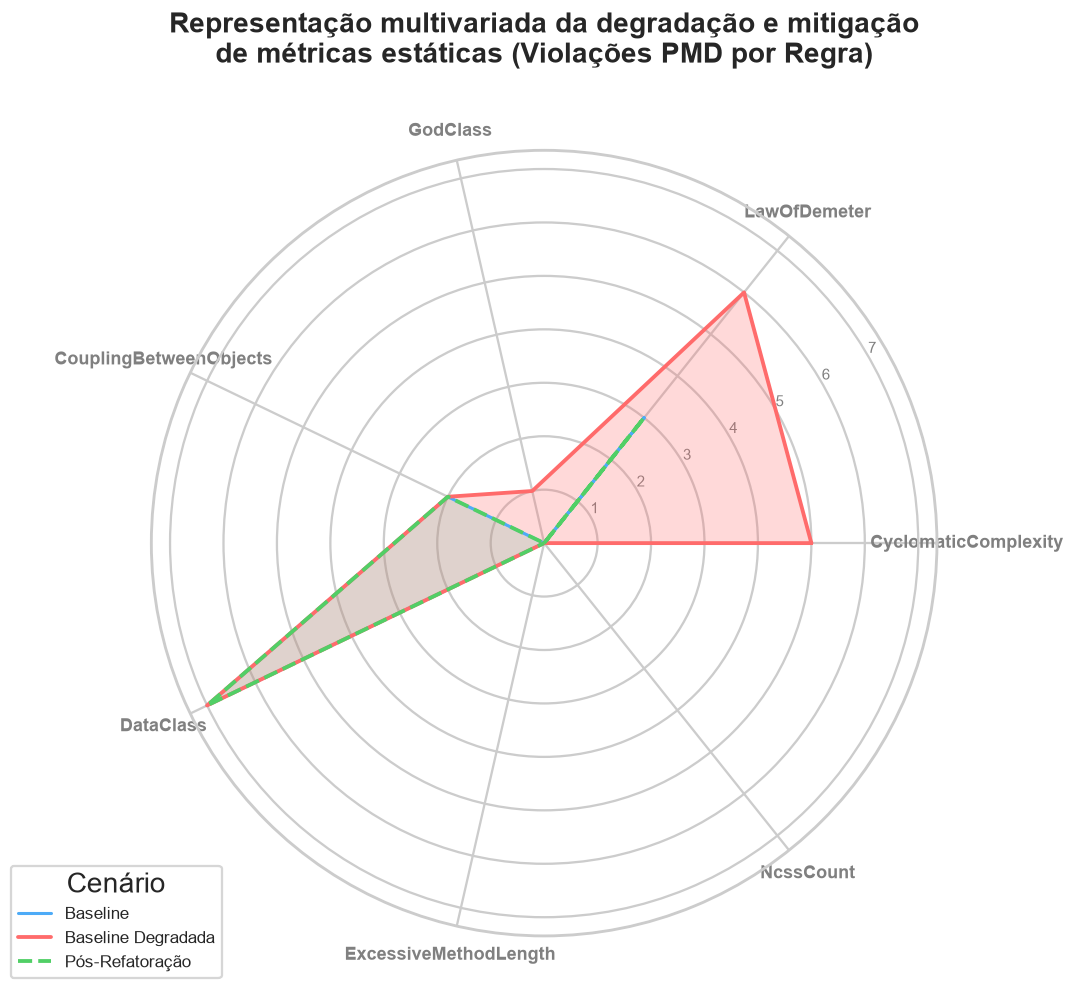

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 8 — Radar comparando o número de violações por regra PMD entre os três cenários. Como os valores são contagens pequenas (0–10 aprox.), a escala não foi normalizada; caso a diferença de escala entre regras cresça no seu conjunto de dados final, normalize cada eixo para [0,1] antes de plotar para evitar que uma única regra domine visualmente o polígono.</i></div>

In [19]:
def plotar_grafico_radar_pmd(df_pmd: pd.DataFrame):
    categorias = df_pmd.index.tolist()
    N = len(categorias)

    valores_baseline = df_pmd["Baseline"].values.tolist()
    valores_degradada = df_pmd["Baseline Degradada"].values.tolist()
    valores_refatorada = df_pmd["Pós-Refatoração"].values.tolist()

    # Fecha o polígono repetindo o primeiro valor
    valores_baseline += valores_baseline[:1]
    valores_degradada += valores_degradada[:1]
    valores_refatorada += valores_refatorada[:1]

    angulos = [n / float(N) * 2 * np.pi for n in range(N)]
    angulos += angulos[:1]

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
    plt.xticks(angulos[:-1], categorias, color="grey", size=12, fontweight="bold")
    ax.set_rlabel_position(30)
    plt.yticks(color="grey", size=10)

    ax.plot(angulos, valores_baseline, linewidth=2, linestyle="solid",
            label="Baseline", color=SCENARIOS["baseline"]["color"])
    ax.fill(angulos, valores_baseline, color=SCENARIOS["baseline"]["color"], alpha=0.1)

    ax.plot(angulos, valores_degradada, linewidth=2.5, linestyle="solid",
            label="Baseline Degradada", color=SCENARIOS["degradada"]["color"])
    ax.fill(angulos, valores_degradada, color=SCENARIOS["degradada"]["color"], alpha=0.25)

    ax.plot(angulos, valores_refatorada, linewidth=2.5, linestyle="dashed",
            label="Pós-Refatoração", color=SCENARIOS["refatorada"]["color"])
    ax.fill(angulos, valores_refatorada, color=SCENARIOS["refatorada"]["color"], alpha=0.1)

    plt.title("Representação multivariada da degradação e mitigação\nde métricas estáticas (Violações PMD por Regra)", size=18, y=1.1)
    plt.legend(loc="upper right", bbox_to_anchor=(0.1, 0.1), fontsize=11, title="Cenário")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figura_08_radar_metricas_pmd.png", dpi=300)
    plt.show()

plotar_grafico_radar_pmd(df_pmd_simples)
legenda("Figura 8 — Radar comparando o número de violações por regra PMD entre os três "
        "cenários. Como os valores são contagens pequenas (0–10 aprox.), a escala não foi "
        "normalizada; caso a diferença de escala entre regras cresça no seu conjunto de "
        "dados final, normalize cada eixo para [0,1] antes de plotar para evitar que uma "
        "única regra domine visualmente o polígono.")

def plotar_grafico_radar_pmd(df_pmd: pd.DataFrame):
    categorias = df_pmd.index.tolist()
    N = len(categorias)

    valores_baseline = df_pmd["Baseline"].values.tolist()
    valores_degradada = df_pmd["Baseline Degradada"].values.tolist()
    valores_refatorada = df_pmd["Pós-Refatoração"].values.tolist()

    # Fecha o polígono repetindo o primeiro valor
    valores_baseline += valores_baseline[:1]
    valores_degradada += valores_degradada[:1]
    valores_refatorada += valores_refatorada[:1]

    angulos = [n / float(N) * 2 * np.pi for n in range(N)]
    angulos += angulos[:1]

    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
    plt.xticks(angulos[:-1], categorias, color="grey", size=12, fontweight="bold")
    ax.set_rlabel_position(30)
    plt.yticks(color="grey", size=10)

    ax.plot(angulos, valores_baseline, linewidth=2, linestyle="solid",
            label="Baseline", color=SCENARIOS["baseline"]["color"])
    ax.fill(angulos, valores_baseline, color=SCENARIOS["baseline"]["color"], alpha=0.1)

    ax.plot(angulos, valores_degradada, linewidth=2.5, linestyle="solid",
            label="Baseline Degradada", color=SCENARIOS["degradada"]["color"])
    ax.fill(angulos, valores_degradada, color=SCENARIOS["degradada"]["color"], alpha=0.25)

    ax.plot(angulos, valores_refatorada, linewidth=2.5, linestyle="dashed",
            label="Pós-Refatoração", color=SCENARIOS["refatorada"]["color"])
    ax.fill(angulos, valores_refatorada, color=SCENARIOS["refatorada"]["color"], alpha=0.1)

    plt.title("Evolução do Débito Técnico (Violações PMD por Regra)", size=18, y=1.1)
    plt.legend(loc="upper right", bbox_to_anchor=(0.1, 0.1), fontsize=11, title="Cenário")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "figura_09_radar_metricas_pmd.png", dpi=300)
    plt.show()

plotar_grafico_radar_pmd(df_pmd_simples)
legenda("Figura 9 — Radar comparando o número de violações por regra PMD entre os três "
        "cenários. Como os valores são contagens pequenas (0–10 aprox.), a escala não foi "
        "normalizada; caso a diferença de escala entre regras cresça no seu conjunto de "
        "dados final, normalize cada eixo para [0,1] antes de plotar para evitar que uma "
        "única regra domine visualmente o polígono.")

In [20]:
def contar_violacoes_layer_archunit(filepath) -> int:
    """Soma o total de violações reportadas pela suíte ValidacaoArquiteturalTest
    (padrão 'was violated (N times)' no log textual do ArchUnit)."""
    if filepath is None or not Path(filepath).exists():
        return 0
    texto = Path(filepath).read_text(encoding="utf-8", errors="ignore")
    ocorrencias = re.findall(r"was violated \((\d+) times\)", texto)
    return sum(int(n) for n in ocorrencias)


def montar_tabela_sintese_estrutural() -> pd.DataFrame:
    """Consolida, em uma única tabela, apenas as métricas estáticas que de fato variaram
    entre os três cenários: violações PMD selecionadas (CC, LawOfDemeter, GodClass) e as
    quatro métricas de acoplamento (Ca/Ce/I/A, ArchUnit) dos pacotes 'rest' e 'repository' —
    os únicos diretamente envolvidos na violação de camada injetada — além da contagem total
    de violações de camada detectadas pela suíte de testes."""
    linhas = []

    regras_sintese = ["CyclomaticComplexity", "LawOfDemeter", "GodClass"]
    for regra in regras_sintese:
        linhas.append({
            "Métrica": f"{regra} — violações (PMD)",
            "Baseline": pmd_contagens["baseline"].get(regra, 0),
            "Baseline Degradada": pmd_contagens["degradada"].get(regra, 0),
            "Pós-Refatoração": pmd_contagens["refatorada"].get(regra, 0),
        })

    pacotes_sintese = ["rest", "repository"]
    metricas_arch = ["Ca", "Ce", "I", "A"]
    for pacote in pacotes_sintese:
        for metrica in metricas_arch:
            linha = {"Métrica": f"{pacote} — {metrica} (ArchUnit)"}
            for cenario_key, cfg in SCENARIOS.items():
                df_ac = archunit_dados[cenario_key]
                valor = df_ac.set_index("pacote")[metrica].get(pacote, np.nan) if not df_ac.empty else np.nan
                linha[cfg["label"]] = valor
            linhas.append(linha)

    linha_violacoes = {"Métrica": "Violações de camada detectadas — ArchUnit"}
    for cenario_key, cfg in SCENARIOS.items():
        linha_violacoes[cfg["label"]] = contar_violacoes_layer_archunit(
            BASE_DIR / cfg["archunit_txt"]
        )
    linhas.append(linha_violacoes)

    return pd.DataFrame(linhas).set_index("Métrica")[ORDEM_CENARIOS]


df_sintese_estrutural = montar_tabela_sintese_estrutural()

display(Markdown("#### Tabela síntese — violações estruturais (PMD + ArchUnit) por cenário"))

LINHAS_DESTAQUE = [
    "CyclomaticComplexity — violações (PMD)",
    "rest — Ce (ArchUnit)",
    "repository — Ca (ArchUnit)",
    "Violações de camada detectadas — ArchUnit",
]

def destacar_sintese(s):
    cor = "background-color: #ffe066; color: black"
    return [cor] * len(s) if s.name in LINHAS_DESTAQUE else [""] * len(s)

display(df_sintese_estrutural.style.format("{:,.3f}", subset=pd.IndexSlice[
    [i for i in df_sintese_estrutural.index if "(ArchUnit)" in i and (" I " in i or " I " in i or i.endswith("I (ArchUnit)") or i.endswith("A (ArchUnit)"))], :
], na_rep="—").format("{:,.0f}", subset=pd.IndexSlice[
    [i for i in df_sintese_estrutural.index if "(PMD)" in i or "(ArchUnit)" in i and ("Ca " in i or "Ce " in i or i.endswith("Ca (ArchUnit)") or i.endswith("Ce (ArchUnit)") or "camada" in i.lower())], :
], na_rep="—").apply(destacar_sintese, axis=1))

legenda("Tabela 5 — Síntese comparativa das violações estruturais identificadas por PMD e "
        "ArchUnit nos três cenários, restrita às métricas que de fato variaram com a "
        "intervenção experimental. Linhas destacadas concentram a evidência mais direta da "
        "hipótese central: o salto de 0→5→0 na Complexidade Ciclomática acompanha, "
        "estruturalmente, o salto de 0→3→0 nas violações de camada (Controller acessando "
        "Repository diretamente); o fan-out (Ce) do pacote rest (3→4→3) quantifica o "
        "Controller passando a depender de uma classe adicional (o Repository, "
        "contornando a camada Service), enquanto o fan-in (Ca) do pacote repository (1→2→1) "
        "mede o mesmo evento pelo lado inverso da dependência — ambos revertidos na "
        "Pós-Refatoração (ISO/IEC 25010, Manutenibilidade).")

df_sintese_estrutural.to_excel(OUTPUT_DIR / "tabela_05_sintese_violacoes_estruturais.xlsx",
                                sheet_name="Tabela_05_Sintese_Estrutural")
print(f"Tabela 5 exportada para: {(OUTPUT_DIR / 'tabela_05_sintese_violacoes_estruturais.xlsx').resolve()}")

#### Tabela síntese — violações estruturais (PMD + ArchUnit) por cenário

,Baseline,Baseline Degradada,Pós-Refatoração
Métrica,,,
CyclomaticComplexity — violações (PMD),0,5,0
LawOfDemeter — violações (PMD),3,6,3
GodClass — violações (PMD),0,1,0
rest — Ca (ArchUnit),1,1,1
rest — Ce (ArchUnit),3,4,3
rest — I (ArchUnit),0.750,0.800,0.750
rest — A (ArchUnit),0.263,0.263,0.263
repository — Ca (ArchUnit),1,2,1
repository — Ce (ArchUnit),2,2,2


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 5 — Síntese comparativa das violações estruturais identificadas por PMD e ArchUnit nos três cenários, restrita às métricas que de fato variaram com a intervenção experimental. Linhas destacadas concentram a evidência mais direta da hipótese central: o salto de 0→5→0 na Complexidade Ciclomática acompanha, estruturalmente, o salto de 0→3→0 nas violações de camada (Controller acessando Repository diretamente); o fan-out (Ce) do pacote rest (3→4→3) quantifica o Controller passando a depender de uma classe adicional (o Repository, contornando a camada Service), enquanto o fan-in (Ca) do pacote repository (1→2→1) mede o mesmo evento pelo lado inverso da dependência — ambos revertidos na Pós-Refatoração (ISO/IEC 25010, Manutenibilidade).</i></div>

Tabela 5 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_05_sintese_violacoes_estruturais.xlsx


## 6. Estatísticas Descritivas (Média, σ, CV%)

Dispersão e estabilidade da latência por endpoint e cenário.


In [21]:
def calcular_estatisticas_descritivas(df_latencia: pd.DataFrame) -> pd.DataFrame:
    """Média, desvio padrão e CV% da latência, por cenário: visão global + por endpoint."""
    linhas = []
    for cenario in df_latencia["Cenário"].cat.categories:
        df_cen = df_latencia[df_latencia["Cenário"] == cenario]
        if df_cen.empty:
            continue

        # 1. Visão global do cenário (todos os endpoints agregados)
        media_g, desvio_g = df_cen["metric_value"].mean(), df_cen["metric_value"].std()
        linhas.append({
            "Cenário": cenario, "Endpoint": "Global (Todos)",
            "Média (ms)": media_g, "Desvio Padrão (ms)": desvio_g,
            "CV (%)": (desvio_g / media_g * 100) if media_g > 0 else 0,
        })

        # 2. Visão por endpoint individual
        for endpoint, serie in df_cen.groupby("Endpoint", observed=True)["metric_value"]:
            media, desvio = serie.mean(), serie.std()
            linhas.append({
                "Cenário": cenario, "Endpoint": endpoint,
                "Média (ms)": media, "Desvio Padrão (ms)": desvio,
                "CV (%)": (desvio / media * 100) if media > 0 else 0,
            })
    return pd.DataFrame(linhas)


df_descritiva = calcular_estatisticas_descritivas(DF_LATENCIA)

df_pivot = df_descritiva.pivot_table(
    index="Endpoint", columns="Cenário",
    values=["Média (ms)", "Desvio Padrão (ms)", "CV (%)"],
    observed=True,
)

# pivot_table ordena as métricas (nível 0 das colunas) alfabeticamente por padrão —
# força de volta a ordem lógica de leitura: Média -> Desvio -> CV.
ordem_metricas = ["Média (ms)", "Desvio Padrão (ms)", "CV (%)"]
df_pivot = df_pivot.reindex(columns=ordem_metricas, level=0)
df_pivot = df_pivot.reindex(columns=ORDEM_CENARIOS, level=1)

ordem_endpoints = ["Global (Todos)"] + sorted(e for e in df_pivot.index if e != "Global (Todos)")
df_pivot = df_pivot.reindex(ordem_endpoints)

def destacar_cv(v):
    """Colore o CV% conforme os limiares definidos na Seção 4.6:
    <10% alta reprodutibilidade (verde), >20% variabilidade excessiva/outlier (vermelho),
    entre 10-20% zona intermediária (laranja)."""
    if pd.isna(v):
        return ""
    if v < 10:
        return "color: #1e8449; font-weight: bold;"
    elif v > 20:
        return "color: #c0392b; font-weight: bold;"
    return "color: #e67e22;"

colunas_media = [c for c in df_pivot.columns if c[0] == "Média (ms)"]
colunas_desvio = [c for c in df_pivot.columns if c[0] == "Desvio Padrão (ms)"]
colunas_cv = [c for c in df_pivot.columns if c[0] == "CV (%)"]

styled_descritiva = (df_pivot.style
    .format({c: "{:,.1f}" for c in colunas_media})
    .format({c: "{:,.1f}" for c in colunas_desvio})
    .format({c: "{:.1f}" for c in colunas_cv})
    .map(destacar_cv, subset=colunas_cv)
    .set_table_styles([{"selector": "th", "props": [("background-color", "#f4f4f4"), ("color", "#333")]}])
)

display(Markdown("#### Tabela 6 — Estatísticas descritivas de latência por endpoint e cenário (Média, Desvio Padrão, CV%)"))
display(styled_descritiva)

df_pivot.to_excel(OUTPUT_DIR / "tabela_06_estatisticas_descritivas_cv.xlsx",
                   sheet_name="Tabela_06_Descritivas_CV")

legenda("Tabela 6 — Média, desvio padrão e coeficiente de variação (CV%) da latência (ms) "
        "por endpoint e cenário, fase steady_state, 5 execuções agregadas por cenário. Critério "
        "de estabilidade (Seção 4.6): CV% < 10% (verde) indica alta reprodutibilidade; CV% > 20% "
        "(vermelho) sugere variabilidade excessiva/candidata a outlier — para a Baseline Degradada, "
        "CV% elevado é esperado e reforçado pela Seção 4.6 como evidência de saturação sistêmica, "
        "não como erro estatístico a ser descartado.")
print(f"Tabela 6 exportada para: {(OUTPUT_DIR / 'tabela_06_estatisticas_descritivas_cv.xlsx').resolve()}")

#### Tabela 6 — Estatísticas descritivas de latência por endpoint e cenário (Média, Desvio Padrão, CV%)

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 6 — Média, desvio padrão e coeficiente de variação (CV%) da latência (ms) por endpoint e cenário, fase steady_state, 5 execuções agregadas por cenário. Critério de estabilidade (Seção 4.6): CV% < 10% (verde) indica alta reprodutibilidade; CV% > 20% (vermelho) sugere variabilidade excessiva/candidata a outlier — para a Baseline Degradada, CV% elevado é esperado e reforçado pela Seção 4.6 como evidência de saturação sistêmica, não como erro estatístico a ser descartado.</i></div>

Tabela 6 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_06_estatisticas_descritivas_cv.xlsx


### 6.1 Latência de Cauda, Vazão e Saturação

Tabelas consolidadas de p95/p99 com CV%, vazão útil e `dropped_iterations`.


In [22]:
def calcular_estatisticas_cauda_por_endpoint(df_latencia: pd.DataFrame) -> pd.DataFrame:
    """Calcula p95 e p99 dentro de cada execução (run) individualmente, agrega média (μ) e
    desvio padrão (σ) entre as 5 execuções -- por endpoint e cenário, mais uma linha 'Global
    (Todos)' -- e deriva o Coeficiente de Variação (CV% = σ/μ × 100) sobre essa dispersão ENTRE
    EXECUÇÕES (não sobre requisições individuais). É esse CV% que a Seção 4.6 usa como critério
    de reprodutibilidade: <10% => alta reprodutibilidade (média validada); >20% => variabilidade
    excessiva, investigada como possível outlier de rodada."""
    linhas = []
    for cenario in df_latencia["Cenário"].cat.categories:
        df_cen = df_latencia[df_latencia["Cenário"] == cenario]
        if df_cen.empty:
            continue

        grupos = [("Global (Todos)", df_cen)] + list(df_cen.groupby("Endpoint", observed=True))
        for endpoint, df_ep in grupos:
            p95_run = df_ep.groupby("run")["metric_value"].quantile(0.95)
            p99_run = df_ep.groupby("run")["metric_value"].quantile(0.99)
            p95_mu, p95_sigma = p95_run.mean(), p95_run.std()
            p99_mu, p99_sigma = p99_run.mean(), p99_run.std()
            linhas.append({
                "Cenário": cenario, "Endpoint": endpoint,
                "p95 μ (ms)": p95_mu, "p95 σ (ms)": p95_sigma,
                "p95 CV (%)": (p95_sigma / p95_mu * 100) if p95_mu else 0,
                "p99 μ (ms)": p99_mu, "p99 σ (ms)": p99_sigma,
                "p99 CV (%)": (p99_sigma / p99_mu * 100) if p99_mu else 0,
            })
    return pd.DataFrame(linhas)


df_cauda = calcular_estatisticas_cauda_por_endpoint(DF_LATENCIA)

df_pivot_cauda = df_cauda.pivot_table(
    index="Endpoint", columns="Cenário",
    values=["p95 μ (ms)", "p95 σ (ms)", "p95 CV (%)", "p99 μ (ms)", "p99 σ (ms)", "p99 CV (%)"],
    observed=True,
)
ordem_metricas_cauda = ["p95 μ (ms)", "p95 σ (ms)", "p95 CV (%)", "p99 μ (ms)", "p99 σ (ms)", "p99 CV (%)"]
df_pivot_cauda = df_pivot_cauda.reindex(columns=ordem_metricas_cauda, level=0)
df_pivot_cauda = df_pivot_cauda.reindex(columns=ORDEM_CENARIOS, level=1)

ordem_endpoints_cauda = ["Global (Todos)"] + sorted(e for e in df_pivot_cauda.index if e != "Global (Todos)")
df_pivot_cauda = df_pivot_cauda.reindex(ordem_endpoints_cauda)


def destacar_cv_reprodutibilidade(v):
    """Critério da Seção 4.6 (CV% entre as 5 execuções): <10% alta reprodutibilidade (verde) --
    média validada; >20% variabilidade excessiva (vermelho) -- candidata a outlier de rodada,
    sujeita à investigação descrita no texto."""
    if pd.isna(v):
        return ""
    if v < 10:
        return "color: #1e8449; font-weight: bold;"
    elif v > 20:
        return "color: #c0392b; font-weight: bold;"
    return "color: #e67e22;"


colunas_cv = [c for c in df_pivot_cauda.columns if "CV" in c[0]]
colunas_mu = [c for c in df_pivot_cauda.columns if "μ" in c[0]]
colunas_sigma = [c for c in df_pivot_cauda.columns if "σ" in c[0]]

styled_cauda = (df_pivot_cauda.style
    .format({c: "{:,.1f}" for c in colunas_mu})
    .format({c: "{:,.1f}" for c in colunas_sigma})
    .format({c: "{:.1f}" for c in colunas_cv})
    .map(destacar_cv_reprodutibilidade, subset=colunas_cv)
    .set_table_styles([{"selector": "th", "props": [("background-color", "#f4f4f4"), ("color", "#333")]}])
)

display(Markdown("#### Tabela 7 — Latência de cauda (p95/p99): média (μ), desvio padrão (σ) e "
                  "Coeficiente de Variação (CV%) entre as 5 execuções, por endpoint e cenário"))
display(styled_cauda)

df_pivot_cauda.to_excel(OUTPUT_DIR / "tabela_07_latencia_cauda_p95_p99.xlsx",
                         sheet_name="Tabela_07_p95_p99_CV")

legenda("Tabela 7 — Percentis de cauda (p95 e p99) da latência (ms), calculados dentro de cada "
        "execução individual e consolidados em média (μ), desvio padrão (σ) e Coeficiente de "
        "Variação (CV% = σ/μ × 100) entre as 5 rodadas, por endpoint e cenário (fase "
        "steady_state). CV% verde (<10%) indica alta reprodutibilidade (Seção 4.6); CV% "
        "vermelho (>20%) indica variabilidade excessiva entre execuções. Na Baseline "
        "Degradada, CV% elevado em vários endpoints (ex.: POST /owners/{id}/pets) reflete a "
        "própria instabilidade comportamental induzida pelo débito técnico sob estresse, não "
        "ruído experimental -- distinção discutida na Seção 4.6.")
print(f"Tabela 7 exportada para: {(OUTPUT_DIR / 'tabela_07_latencia_cauda_p95_p99.xlsx').resolve()}")

#### Tabela 7 — Latência de cauda (p95/p99): média (μ), desvio padrão (σ) e Coeficiente de Variação (CV%) entre as 5 execuções, por endpoint e cenário

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 7 — Percentis de cauda (p95 e p99) da latência (ms), calculados dentro de cada execução individual e consolidados em média (μ), desvio padrão (σ) e Coeficiente de Variação (CV% = σ/μ × 100) entre as 5 rodadas, por endpoint e cenário (fase steady_state). CV% verde (<10%) indica alta reprodutibilidade (Seção 4.6); CV% vermelho (>20%) indica variabilidade excessiva entre execuções. Na Baseline Degradada, CV% elevado em vários endpoints (ex.: POST /owners/{id}/pets) reflete a própria instabilidade comportamental induzida pelo débito técnico sob estresse, não ruído experimental -- distinção discutida na Seção 4.6.</i></div>

Tabela 7 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_07_latencia_cauda_p95_p99.xlsx


In [23]:
def calcular_vazao_util_e_saturacao(df_execucoes: pd.DataFrame) -> pd.DataFrame:
    """Vazão bruta e vazão útil (requisições que de fato completaram com sucesso -- vazão bruta
    ponderada pela taxa de acerto), além do indicador de saturação (dropped_iterations, ver
    Seção 3.1), agregados em média (μ) e desvio padrão (σ) entre as 5 execuções, por cenário."""
    df = df_execucoes.copy()
    df["vazao_util_reqs_s"] = df["throughput_http_reqs_s"] * (1 - df["taxa_erro_global"])

    linhas = []
    for cenario_key, cfg in SCENARIOS.items():
        df_cen = df[df["cenario"] == cenario_key]
        if df_cen.empty:
            continue
        linhas.append({
            "Cenário": cfg["label"],
            "Vazão Bruta μ (req/s)": df_cen["throughput_http_reqs_s"].mean(),
            "Vazão Bruta σ (req/s)": df_cen["throughput_http_reqs_s"].std(),
            "Vazão Útil μ (req/s)": df_cen["vazao_util_reqs_s"].mean(),
            "Vazão Útil σ (req/s)": df_cen["vazao_util_reqs_s"].std(),
            "Taxa de Erro μ (%)": df_cen["taxa_erro_global"].mean() * 100,
            "Dropped Iterations μ": df_cen["dropped_iterations"].mean(),
            "Dropped Iterations σ": df_cen["dropped_iterations"].std(),
        })
    return pd.DataFrame(linhas).set_index("Cenário").reindex(ORDEM_CENARIOS)


df_vazao_saturacao = calcular_vazao_util_e_saturacao(df_execucoes)

display(Markdown("#### Vazão útil e saturação — média (μ) e desvio padrão (σ) entre as 5 execuções, por cenário"))
styled_vazao = df_vazao_saturacao.style.format({
    "Vazão Bruta μ (req/s)": "{:,.2f}", "Vazão Bruta σ (req/s)": "{:,.2f}",
    "Vazão Útil μ (req/s)": "{:,.2f}", "Vazão Útil σ (req/s)": "{:,.2f}",
    "Taxa de Erro μ (%)": "{:,.2f}",
    "Dropped Iterations μ": "{:,.1f}", "Dropped Iterations σ": "{:,.1f}",
}).set_table_styles([
    {"selector": "th", "props": [("background-color", "#f4f4f4"), ("color", "#333")]}
])
display(styled_vazao)
legenda("Tabela 8 — Vazão bruta (throughput_http_reqs_s), vazão útil (vazão bruta × (1 − taxa "
        "de erro global), representando apenas as requisições que efetivamente completaram "
        "com sucesso) e indicador de saturação (dropped_iterations, extraído do summary.json "
        "-- Seção 3.1), agregados em média (μ) e desvio padrão (σ) entre as 5 execuções de "
        "cada cenário. Dropped_iterations consistentemente > 0 indica que o cenário não "
        "sustentou a taxa alvo do executor constant-arrival-rate (26 it/s), configurando "
        "quebra de resiliência sistêmica sob carga aberta (open-loop) -- e não um artefato "
        "isolado de uma única rodada.")

df_vazao_saturacao.to_excel(OUTPUT_DIR / "tabela_08_vazao_saturacao.xlsx",
                             sheet_name="Tabela_08_Vazao_Saturacao")
print(f"Tabela 8 exportada para: {(OUTPUT_DIR / 'tabela_08_vazao_saturacao.xlsx').resolve()}")

#### Vazão útil e saturação — média (μ) e desvio padrão (σ) entre as 5 execuções, por cenário

,Vazão Bruta μ (req/s),Vazão Bruta σ (req/s),Vazão Útil μ (req/s),Vazão Útil σ (req/s),Taxa de Erro μ (%),Dropped Iterations μ,Dropped Iterations σ
Cenário,,,,,,,
Baseline,55.07,0.87,55.07,0.87,0.00,"12,888.4",77.1
Baseline Degradada,27.20,0.48,25.52,0.54,6.18,"15,851.4",66.0
Pós-Refatoração,64.99,0.43,64.99,0.43,0.00,"11,863.6",35.1


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 8 — Vazão bruta (throughput_http_reqs_s), vazão útil (vazão bruta × (1 − taxa de erro global), representando apenas as requisições que efetivamente completaram com sucesso) e indicador de saturação (dropped_iterations, extraído do summary.json -- Seção 3.1), agregados em média (μ) e desvio padrão (σ) entre as 5 execuções de cada cenário. Dropped_iterations consistentemente > 0 indica que o cenário não sustentou a taxa alvo do executor constant-arrival-rate (26 it/s), configurando quebra de resiliência sistêmica sob carga aberta (open-loop) -- e não um artefato isolado de uma única rodada.</i></div>

Tabela 8 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_08_vazao_saturacao.xlsx


## 7. Significância Estatística e Tamanho do Efeito

Mann-Whitney U (p-value) e Cliff's Delta por endpoint e par de cenários.


In [24]:
def teste_mann_whitney(amostra_a: pd.Series, amostra_b: pd.Series, alpha: float = 0.05) -> dict:
    a = pd.to_numeric(amostra_a, errors="coerce").dropna()
    b = pd.to_numeric(amostra_b, errors="coerce").dropna()
    if len(a) < 2 or len(b) < 2:
        return {"N_a": len(a), "N_b": len(b), "Estatística U": np.nan, "p-value": np.nan,
                "Significativo (p<0.05)": None}
    estatistica, p_valor = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {"N_a": len(a), "N_b": len(b), "Estatística U": estatistica, "p-value": p_valor,
            "Significativo (p<0.05)": bool(p_valor < alpha)}


def cliffs_delta(amostra_a: pd.Series, amostra_b: pd.Series) -> dict:
    a = pd.to_numeric(amostra_a, errors="coerce").dropna().to_numpy()
    b = pd.to_numeric(amostra_b, errors="coerce").dropna().to_numpy()
    n_a, n_b = len(a), len(b)
    if n_a == 0 or n_b == 0:
        return {"Delta": np.nan, "Magnitude": "Indefinido"}

    ranks = stats.rankdata(np.concatenate([a, b]))
    soma_ranks_a = ranks[:n_a].sum()
    u_estatistica = soma_ranks_a - (n_a * (n_a + 1)) / 2
    delta = (2 * u_estatistica / (n_a * n_b)) - 1
    abs_delta = abs(delta)

    if abs_delta < 0.147: magnitude = "Negligível"
    elif abs_delta < 0.33: magnitude = "Pequeno"
    elif abs_delta < 0.474: magnitude = "Médio"
    else: magnitude = "Grande"
    return {"Delta": delta, "Magnitude": magnitude}


def executar_testes_por_endpoint(df_latencia: pd.DataFrame) -> pd.DataFrame:
    """Roda Mann-Whitney + Cliff's Delta para cada par de cenários consecutivos
    (Baseline->Degradada, Degradada->Pós-Refatoração), quebrado por endpoint + um
    resumo 'Global (Todos)' agregando todas as requisições."""
    pares = [("Baseline", "Baseline Degradada"), ("Baseline Degradada", "Pós-Refatoração")]
    endpoints = ["Global (Todos)"] + sorted(df_latencia["Endpoint"].dropna().unique().tolist())

    resultados = []
    for cenario_a, cenario_b in pares:
        for endpoint in endpoints:
            if endpoint == "Global (Todos)":
                serie_a = df_latencia.loc[df_latencia["Cenário"] == cenario_a, "metric_value"]
                serie_b = df_latencia.loc[df_latencia["Cenário"] == cenario_b, "metric_value"]
            else:
                serie_a = df_latencia.loc[
                    (df_latencia["Cenário"] == cenario_a) & (df_latencia["Endpoint"] == endpoint),
                    "metric_value"]
                serie_b = df_latencia.loc[
                    (df_latencia["Cenário"] == cenario_b) & (df_latencia["Endpoint"] == endpoint),
                    "metric_value"]

            mw = teste_mann_whitney(serie_a, serie_b)
            cd = cliffs_delta(serie_a, serie_b)
            resultados.append({
                "Comparação": f"{cenario_a} → {cenario_b}",
                "Endpoint": endpoint,
                **mw, **cd,
            })
    return pd.DataFrame(resultados)


df_testes = executar_testes_por_endpoint(DF_LATENCIA)

for comparacao in df_testes["Comparação"].unique():
    display(Markdown(f"#### {comparacao}"))
    tabela = df_testes[df_testes["Comparação"] == comparacao].drop(columns=["Comparação"]).set_index("Endpoint")

    def destacar_magnitude(v):
        if v == "Grande": return "color: #c0392b; font-weight: bold;"
        if v == "Médio": return "color: #e67e22; font-weight: bold;"
        return ""

    styled = (tabela.style
              .format({"N_a": "{:,.0f}", "N_b": "{:,.0f}", "Estatística U": "{:,.0f}",
                        "p-value": "{:.2e}", "Delta": "{:,.4f}"})
              .map(destacar_magnitude, subset=["Magnitude"]))
    display(styled)

legenda("Tabela 9 — Teste de Mann-Whitney U (significância) e Cliff's Delta (tamanho do "
        "efeito) por endpoint, comparando cenários consecutivos. N_a/N_b = tamanho amostral "
        "de cada lado. Magnitudes 'Médio' e 'Grande' estão destacadas: são os candidatos mais "
        "fortes para sustentar (ou refutar, se o sinal do Delta for inesperado) a hipótese "
        "central na Seção 5.4 do estudo de caso.")

# Exportação da Tabela 9 (formato longo, um registro por comparacao x endpoint)
df_testes.to_excel(OUTPUT_DIR / "tabela_09_mannwhitney_cliffsdelta_detalhado.xlsx",
                    sheet_name="Tabela_09_MW_CD_Detalhado", index=False)
print(f"Tabela 9 exportada para: {(OUTPUT_DIR / 'tabela_09_mannwhitney_cliffsdelta_detalhado.xlsx').resolve()}")

#### Baseline → Baseline Degradada

,N_a,N_b,Estatística U,p-value,Significativo (p<0.05),Delta,Magnitude
Endpoint,,,,,,,
Global (Todos),"172,184","80,702","6,454,052,796",4.65e-183,True,-0.0711,Negligível
GET /owners,"29,107","13,719","19,740,346",0.00e+00,True,-0.9011,Grande
GET /owners/{id},"28,869","13,495","222,042,354",2.04e-119,True,0.1399,Negligível
GET /vets,"28,205","13,184","199,768,382",2.39e-34,True,0.0744,Negligível
POST /owners,"28,986","13,607","177,715,348",5.73e-61,True,-0.0988,Negligível
POST /owners/{id}/pets,"28,620","13,473","239,841,363",0.00e+00,True,0.2440,Pequeno
POST /owners/{id}/pets/{pid}/visits,"28,397","13,224","199,622,232",2.67e-25,True,0.0632,Negligível


#### Baseline Degradada → Pós-Refatoração

,N_a,N_b,Estatística U,p-value,Significativo (p<0.05),Delta,Magnitude
Endpoint,,,,,,,
Global (Todos),"80,702","204,438","10,746,008,604",0.00e+00,True,0.3027,Pequeno
GET /owners,"13,719","34,207","443,786,008",0.00e+00,True,0.8913,Grande
GET /owners/{id},"13,495","34,095","251,967,917",3.59e-59,True,0.0952,Negligível
GET /vets,"13,184","33,968","351,338,169",0.00e+00,True,0.5691,Grande
POST /owners,"13,607","34,128","297,042,638",0.00e+00,True,0.2793,Pequeno
POST /owners/{id}/pets,"13,473","34,045","246,837,505",1.59e-38,True,0.0763,Negligível
POST /owners/{id}/pets/{pid}/visits,"13,224","33,995","258,706,636",1.45e-143,True,0.1510,Pequeno


<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 9 — Teste de Mann-Whitney U (significância) e Cliff's Delta (tamanho do efeito) por endpoint, comparando cenários consecutivos. N_a/N_b = tamanho amostral de cada lado. Magnitudes 'Médio' e 'Grande' estão destacadas: são os candidatos mais fortes para sustentar (ou refutar, se o sinal do Delta for inesperado) a hipótese central na Seção 5.4 do estudo de caso.</i></div>

Tabela 9 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_09_mannwhitney_cliffsdelta_detalhado.xlsx


### 7.1 Tabela Consolidada: Mann-Whitney U e Cliff's Delta

Síntese dos testes estatísticos nas comparações Original→Degradada e Degradada→Refatorada.


In [25]:
def teste_robustez_por_rodada(df_runs: pd.DataFrame, coluna: str) -> pd.DataFrame:
    """Replica Mann-Whitney U + Cliff's Delta usando a métrica agregada por execução
    (uma observação por rodada, N=5 por cenário) como unidade amostral — unidades
    genuinamente independentes entre si. Checagem de robustez frente à pseudo-replicação
    da análise em nível de requisição (Tabela 9)."""
    pares = [("Baseline", "Baseline Degradada"), ("Baseline Degradada", "Pós-Refatoração")]
    resultados = []
    for cenario_a, cenario_b in pares:
        serie_a = df_runs.loc[df_runs["cenario"] == cenario_a, coluna]
        serie_b = df_runs.loc[df_runs["cenario"] == cenario_b, coluna]
        resultados.append({
            "Comparação": f"{cenario_a} → {cenario_b}", "Métrica": coluna,
            **teste_mann_whitney(serie_a, serie_b), **cliffs_delta(serie_a, serie_b),
        })
    return pd.DataFrame(resultados)

df_robustez = pd.concat([
    teste_robustez_por_rodada(df_runs, "mediana_ms"),
    teste_robustez_por_rodada(df_runs, "p95_ms"),
], ignore_index=True)
display(df_robustez)

,Comparação,Métrica,N_a,N_b,Estatística U,p-value,Significativo (p<0.05),Delta,Magnitude
0,Baseline → Baseline Degradada,mediana_ms,5,5,25.0,0.007937,True,1.0,Grande
1,Baseline Degradada → Pós-Refatoração,mediana_ms,5,5,25.0,0.007937,True,1.0,Grande
2,Baseline → Baseline Degradada,p95_ms,5,5,0.0,0.007937,True,-1.0,Grande
3,Baseline Degradada → Pós-Refatoração,p95_ms,5,5,25.0,0.007937,True,1.0,Grande


In [26]:
def montar_tabela5_consolidada(df_testes: pd.DataFrame) -> pd.DataFrame:
    """Pivota df_testes (formato longo: uma linha por Endpoint x Comparação) para uma
    tabela única em formato largo: uma linha por Endpoint, com colunas de p-value, Delta
    (Cliff's Delta) e Magnitude repetidas para cada comparação — Original vs. Degradada e
    Degradada vs. Refatorada — lado a lado."""
    pares_ordem = ["Baseline → Baseline Degradada", "Baseline Degradada → Pós-Refatoração"]
    rotulos_pares = {
        "Baseline → Baseline Degradada": "Original → Degradada",
        "Baseline Degradada → Pós-Refatoração": "Degradada → Refatorada",
    }

    blocos = []
    for par in pares_ordem:
        sub = df_testes[df_testes["Comparação"] == par].set_index("Endpoint")[["p-value", "Delta", "Magnitude"]]
        sub.columns = pd.MultiIndex.from_product([[rotulos_pares[par]], sub.columns])
        blocos.append(sub)

    tabela10 = pd.concat(blocos, axis=1)
    ordem_endpoints = ["Global (Todos)"] + sorted(e for e in tabela10.index if e != "Global (Todos)")
    tabela10 = tabela10.reindex(ordem_endpoints)
    return tabela10


tabela10 = montar_tabela5_consolidada(df_testes)


def destacar_magnitude10(v):
    if v == "Grande":
        return "color: #c0392b; font-weight: bold;"
    if v == "Médio":
        return "color: #e67e22; font-weight: bold;"
    return ""


colunas_pvalue = [c for c in tabela10.columns if c[1] == "p-value"]
colunas_delta = [c for c in tabela10.columns if c[1] == "Delta"]
colunas_magnitude = [c for c in tabela10.columns if c[1] == "Magnitude"]

styled10 = (tabela10.style
           .format({c: "{:.2e}" for c in colunas_pvalue})
           .format({c: "{:,.4f}" for c in colunas_delta})
           .map(destacar_magnitude10, subset=colunas_magnitude))

display(Markdown("#### Tabela 10 — Mann-Whitney U (p-value) e Cliff's Delta por Endpoint "
                  "— Original vs. Degradada e Degradada vs. Refatorada"))
display(styled10)

tabela10.to_excel(OUTPUT_DIR / "tabela_10_mannwhitney_cliffsdelta_consolidada.xlsx",
                   sheet_name="Tabela_10_MW_CD_Consolidada")

legenda("Tabela 10 — Síntese consolidada do teste de Mann-Whitney U (p-value) e do tamanho do "
        "efeito (Cliff's Delta) por endpoint, comparando lado a lado Original → Degradada e "
        "Degradada → Refatorada. Magnitudes 'Médio' e 'Grande' destacadas em laranja/vermelho.")
print(f"Tabela 10 exportada para: {(OUTPUT_DIR / 'tabela_10_mannwhitney_cliffsdelta_consolidada.xlsx').resolve()}")

#### Tabela 10 — Mann-Whitney U (p-value) e Cliff's Delta por Endpoint — Original vs. Degradada e Degradada vs. Refatorada

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Tabela 10 — Síntese consolidada do teste de Mann-Whitney U (p-value) e do tamanho do efeito (Cliff's Delta) por endpoint, comparando lado a lado Original → Degradada e Degradada → Refatorada. Magnitudes 'Médio' e 'Grande' destacadas em laranja/vermelho.</i></div>

Tabela 10 exportada para: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_10_mannwhitney_cliffsdelta_consolidada.xlsx


## 8. Exportação (.xlsx / .csv / .png)

Gera todos os artefatos de saída parametrizados pelo cenário na pasta `resultados_estatisticos_{UV_CENARIO}/`.


In [27]:
# --- Métricas adicionais de throughput em bytes (necessárias apenas para a aba "Throughput") ---
registros_bytes = []
for cenario_key, cfg in SCENARIOS.items():
    for fp in sorted(BASE_DIR.glob(cfg["k6_json_glob"])):
        run_match = re.search(r"run_(\d+)", fp.name)
        run_number = int(run_match.group(1)) if run_match else 0
        raw_metrics = carregar_k6_json_run(fp).get("raw", {}).get("metrics", {})
        registros_bytes.append({
            "cenario": cenario_key, "run": run_number,
            "data_received_rate": raw_metrics.get("data_received", {}).get("values", {}).get("rate", np.nan),
            "data_sent_rate": raw_metrics.get("data_sent", {}).get("values", {}).get("rate", np.nan),
        })
df_bytes = pd.DataFrame(registros_bytes)
df_execucoes_full = df_execucoes.merge(df_bytes, on=["cenario", "run"], how="left")
print(f"Métricas de throughput em bytes anexadas a {len(df_bytes)} execuções.")

Métricas de throughput em bytes anexadas a 15 execuções.


In [28]:
def montar_df_metrica_por_endpoint(dados_k6: dict, metric_name: str, agregacao) -> pd.DataFrame:
    """Generaliza a extração por (Cenário, Endpoint, run) para qualquer métrica do K6
    (ex.: http_req_duration -> quantis; http_req_failed -> média/taxa)."""
    frames = []
    for nome_cenario, df in dados_k6.items():
        if df.empty:
            continue
        df_m = df[df["metric_name"] == metric_name].copy()
        df_m = df_m[df_m["group"].isin(ENDPOINTS_VALIDOS.keys())]
        df_m["Cenário"] = SCENARIOS[nome_cenario]["label"]
        df_m["Endpoint"] = df_m["group"].map(ENDPOINTS_VALIDOS)
        frames.append(df_m)
    if not frames:
        return pd.DataFrame()
    df_all = pd.concat(frames, ignore_index=True)
    resultado = (df_all.groupby(["Cenário", "Endpoint", "run"])["metric_value"]
                 .agg(agregacao).reset_index(name="valor"))
    return resultado


DF_P95_RUN = montar_df_metrica_por_endpoint(dados_k6, "http_req_duration", lambda s: s.quantile(0.95))
DF_P99_RUN = montar_df_metrica_por_endpoint(dados_k6, "http_req_duration", lambda s: s.quantile(0.99))
DF_ERRO_RUN = montar_df_metrica_por_endpoint(dados_k6, "http_req_failed", "mean")

ORDEM_ENDPOINTS_XLSX = [
    "GET /owners", "POST /owners", "GET /owners/{id}",
    "POST /owners/{id}/pets", "POST /owners/{id}/pets/{pid}/visits", "GET /vets",
]

In [29]:
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

BORDA_FINA = Border(*[Side(style="thin", color="CCCCCC")] * 4)
FUNDO_TITULO = PatternFill("solid", fgColor="2F5496")
FUNDO_CABECALHO = PatternFill("solid", fgColor="D9E1F2")
FONTE_TITULO = Font(bold=True, color="FFFFFF", size=13)
FONTE_CABECALHO = Font(bold=True, size=10)
CENTRO = Alignment(horizontal="center", vertical="center", wrap_text=True)


def _runs_disponiveis(cenario_key: str) -> list:
    runs = sorted(dados_k6[cenario_key]["run"].unique().tolist()) if not dados_k6[cenario_key].empty else []
    return runs or list(range(1, N_RUNS_ESPERADO + 1))


def _escrever_bloco_metrica(ws, df_metrica: pd.DataFrame, titulo: str, formato_num: str,
                             linha_delta_pct: bool = True):
    """Escreve uma aba no padrão do modelo: Endpoint | Run1..RunN Média±σ | (repetido por
    cenário) | Δ entre Baseline Degradada e Pós-Refatoração."""
    cenarios = list(SCENARIOS.keys())
    max_runs = max(len(_runs_disponiveis(c)) for c in cenarios)
    col = 2  # coluna B: primeira coluna de dados (A é reservada para o nome do endpoint)
    blocos = {}  # cenario_key -> (col_inicio, col_fim)

    # Linha de título
    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=1 + len(cenarios) * (max_runs + 1) + 1)
    c = ws.cell(row=1, column=1, value=titulo)
    c.font = FONTE_TITULO
    c.fill = FUNDO_TITULO
    c.alignment = CENTRO

    # Linha de cabeçalho de cenário (mesclada) + sub-cabeçalho de runs
    ws.cell(row=2, column=1, value="Endpoint").font = FONTE_CABECALHO
    ws.merge_cells(start_row=2, start_column=1, end_row=3, end_column=1)
    for cenario_key in cenarios:
        label = SCENARIOS[cenario_key]["label"]
        n_runs = max_runs
        ws.merge_cells(start_row=2, start_column=col, end_row=2, end_column=col + n_runs)
        cab = ws.cell(row=2, column=col, value=f"{label.upper()} ({n_runs} runs)")
        cab.font = FONTE_CABECALHO
        cab.fill = FUNDO_CABECALHO
        cab.alignment = CENTRO
        for i in range(n_runs):
            ws.cell(row=3, column=col + i, value=f"Run {i + 1}").font = FONTE_CABECALHO
        ws.cell(row=3, column=col + n_runs, value="Média ± σ").font = FONTE_CABECALHO
        blocos[cenario_key] = (col, col + n_runs)
        col += n_runs + 1

    col_delta = col
    if linha_delta_pct:
        ws.cell(row=2, column=col_delta, value="Δ (Degradada → Pós-Refatoração)").font = FONTE_CABECALHO
        ws.merge_cells(start_row=2, start_column=col_delta, end_row=3, end_column=col_delta)

    # Linhas de dados por endpoint
    linha = 4
    for endpoint in ORDEM_ENDPOINTS_XLSX:
        ws.cell(row=linha, column=1, value=endpoint).font = Font(bold=True)
        medias = {}
        for cenario_key in cenarios:
            label = SCENARIOS[cenario_key]["label"]
            col_ini, col_fim = blocos[cenario_key]
            valores_runs = df_metrica[(df_metrica["Cenário"] == label) & (df_metrica["Endpoint"] == endpoint)]
            valores_runs = valores_runs.set_index("run")["valor"]
            for i, run_n in enumerate(_runs_disponiveis(cenario_key)):
                v = valores_runs.get(run_n, np.nan)
                ws.cell(row=linha, column=col_ini + i, value=(None if pd.isna(v) else round(float(v), 4)))
            media = valores_runs.mean()
            desvio = valores_runs.std()
            medias[cenario_key] = media
            texto_media = "" if pd.isna(media) else f"{media:{formato_num}} ± {desvio:{formato_num}}"
            ws.cell(row=linha, column=col_fim, value=texto_media).font = Font(bold=True)

        if linha_delta_pct and "degradada" in medias and "pos_refatoracao" in medias:
            m_deg, m_pos = medias["degradada"], medias["pos_refatoracao"]
            if pd.notna(m_deg) and pd.notna(m_pos) and m_deg != 0:
                delta_pct = (m_pos - m_deg) / m_deg * 100
                cel = ws.cell(row=linha, column=col_delta, value=f"{delta_pct:+.1f}%")
                cel.font = Font(bold=True, color=("C00000" if delta_pct > 0 else "375623"))
        linha += 1

    for row in ws.iter_rows(min_row=1, max_row=linha - 1, min_col=1, max_col=col_delta):
        for cell in row:
            cell.border = BORDA_FINA
    ws.column_dimensions["A"].width = 32
    for c_idx in range(2, col_delta + 1):
        ws.column_dimensions[get_column_letter(c_idx)].width = 12


def gerar_planilha_consolidada(caminho_saida: Path):
    wb = openpyxl.Workbook()
    wb.remove(wb.active)

    # --- Aba 1: Execuções (metadados de cada rodada) ---
    ws_exec = wb.create_sheet("Execuções")
    ws_exec.append(["TCC — Registro de Execuções Benchmark (K6)"])
    ws_exec["A1"].font = FONTE_TITULO
    ws_exec["A1"].fill = FUNDO_TITULO
    ws_exec.append(["Run", "Cenário (Fase)", "Branch Git (esperada)", "CSV", "JSON Summary"])
    for cell in ws_exec[2]:
        cell.font = FONTE_CABECALHO
        cell.fill = FUNDO_CABECALHO
    linha = 3
    for cenario_key, cfg in SCENARIOS.items():
        for i, fp in enumerate(sorted(BASE_DIR.glob(cfg["k6_csv_glob"])), start=1):
            run_match = re.search(r"run_(\d+)", fp.name)
            run_n = int(run_match.group(1)) if run_match else i
            json_match = next((j.name for j in sorted(BASE_DIR.glob(cfg["k6_json_glob"]))
                                if f"run_{run_n}-" in j.name), "")
            ws_exec.append([run_n, cfg["label"], cfg["k6_csv_glob"].split("/")[-1].split("_run_")[0],
                             fp.name, json_match])
            linha += 1
    for col, width in zip("ABCDE", [6, 20, 45, 55, 55]):
        ws_exec.column_dimensions[col].width = width

    # --- Abas 2-4: p95, p99, Taxa de Erros ---
    ws_p95 = wb.create_sheet("Resultados_p95")
    _escrever_bloco_metrica(ws_p95, DF_P95_RUN, "TCC — p95 de Latência por Endpoint (ms)", ",.1f")

    ws_p99 = wb.create_sheet("Resultados_p99")
    _escrever_bloco_metrica(ws_p99, DF_P99_RUN, "TCC — p99 de Latência por Endpoint (ms)", ",.1f")

    ws_erro = wb.create_sheet("Taxa_Erros")
    _escrever_bloco_metrica(ws_erro, DF_ERRO_RUN, "TCC — Taxa de Erros por Endpoint (fração, 4 casas decimais)", ".4f")

    # --- Aba 5: Throughput (métricas globais, não por endpoint) ---
    ws_thr = wb.create_sheet("Throughput")
    ws_thr.append(["TCC — Throughput (req/s, iter/s, bytes/s) por Cenário"])
    ws_thr["A1"].font = FONTE_TITULO
    ws_thr["A1"].fill = FUNDO_TITULO
    metricas_throughput = [
        ("http_reqs.rate (req/s)", "throughput_http_reqs_s"),
        ("iterations.rate (iter/s)", "throughput_iteracoes_s"),
        ("data_received.rate (bytes/s)", "data_received_rate"),
        ("data_sent.rate (bytes/s)", "data_sent_rate"),
    ]
    col = 2
    linha_cab = 2
    ws_thr.cell(row=linha_cab, column=1, value="Métrica").font = FONTE_CABECALHO
    blocos_thr = {}
    for cenario_key, cfg in SCENARIOS.items():
        n_runs = len(_runs_disponiveis(cenario_key))
        ws_thr.merge_cells(start_row=linha_cab, start_column=col, end_row=linha_cab, end_column=col + n_runs)
        cab = ws_thr.cell(row=linha_cab, column=col, value=cfg["label"].upper())
        cab.font, cab.fill, cab.alignment = FONTE_CABECALHO, FUNDO_CABECALHO, CENTRO
        blocos_thr[cenario_key] = col
        col += n_runs + 1
    linha = linha_cab + 1
    for rotulo, campo in metricas_throughput:
        ws_thr.cell(row=linha, column=1, value=rotulo).font = Font(bold=True)
        for cenario_key, cfg in SCENARIOS.items():
            col_ini = blocos_thr[cenario_key]
            df_sub = df_execucoes_full[df_execucoes_full["cenario"] == cenario_key].sort_values("run")
            for i, (_, row) in enumerate(df_sub.iterrows()):
                v = row.get(campo, np.nan)
                ws_thr.cell(row=linha, column=col_ini + i, value=(None if pd.isna(v) else round(float(v), 2)))
            media = df_sub[campo].mean()
            n_runs = len(_runs_disponiveis(cenario_key))
            ws_thr.cell(row=linha, column=col_ini + n_runs,
                        value=(None if pd.isna(media) else f"média: {media:,.2f}")).font = Font(italic=True)
        linha += 1
    ws_thr.column_dimensions["A"].width = 30

    wb.save(caminho_saida)
    print(f"Planilha consolidada salva em: {caminho_saida.resolve()}")


CAMINHO_XLSX = OUTPUT_DIR / "tabela_11_resultados_consolidados.xlsx"
gerar_planilha_consolidada(CAMINHO_XLSX)

Planilha consolidada salva em: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_11_resultados_consolidados.xlsx


In [ ]:
def contagem_cumulativa_owners_criados(dados_k6: dict, cenario: str = "degradada") -> pd.DataFrame:
    """Retorna a contagem cumulativa de owners criados com sucesso por run ao longo do tempo."""
    if cenario not in dados_k6:
        disponiveis = ", ".join(sorted(dados_k6.keys()))
        raise KeyError(f"Cenario '{cenario}' nao encontrado em dados_k6. Disponiveis: {disponiveis}")

    df = dados_k6[cenario]
    if df.empty:
        return pd.DataFrame(columns=["run", "Tempo (s)", "owners_cumulativo"])

    filtro = (df["metric_name"] == "http_req_failed") & (df["group"] == "::POST /owners")
    df_post = df.loc[filtro, ["run", "timestamp", "metric_value"]].copy()
    if df_post.empty:
        return pd.DataFrame(columns=["run", "Tempo (s)", "owners_cumulativo"])

    df_post["datetime"] = pd.to_datetime(df_post["timestamp"], unit="s")
    df_post["Tempo (s)"] = df_post.groupby("run")["datetime"].transform(
        lambda s: (s - s.min()).dt.total_seconds()
    )

    df_sucesso = df_post[df_post["metric_value"] == 0].copy()
    if df_sucesso.empty:
        return pd.DataFrame(columns=["run", "Tempo (s)", "owners_cumulativo"])

    df_sucesso = df_sucesso.sort_values(["run", "Tempo (s)"]).reset_index(drop=True)
    df_sucesso["owners_cumulativo"] = df_sucesso.groupby("run").cumcount() + 1

    return df_sucesso[["run", "Tempo (s)", "owners_cumulativo"]]

Cenario analisado: Baseline Degradada (degradada)
Branch/dataset considerado: k6-metrics-refactoring-metrics-intentional-code-smells


#### Contagem cumulativa de owners criados com sucesso (POST /owners)

,run,Tempo (s),owners_cumulativo
0,1,0.0,1
1,1,0.0,2
2,1,0.0,3
3,1,0.0,4
4,1,0.0,5
5,1,0.0,6
6,1,0.0,7
7,1,0.0,8
8,1,0.0,9
9,1,0.0,10


Total de linhas: 13,607
CSV salvo em: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_12_owners_cumulativo_degradada.csv
XLSX salvo em: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/tabela_12_owners_cumulativo_degradada.xlsx


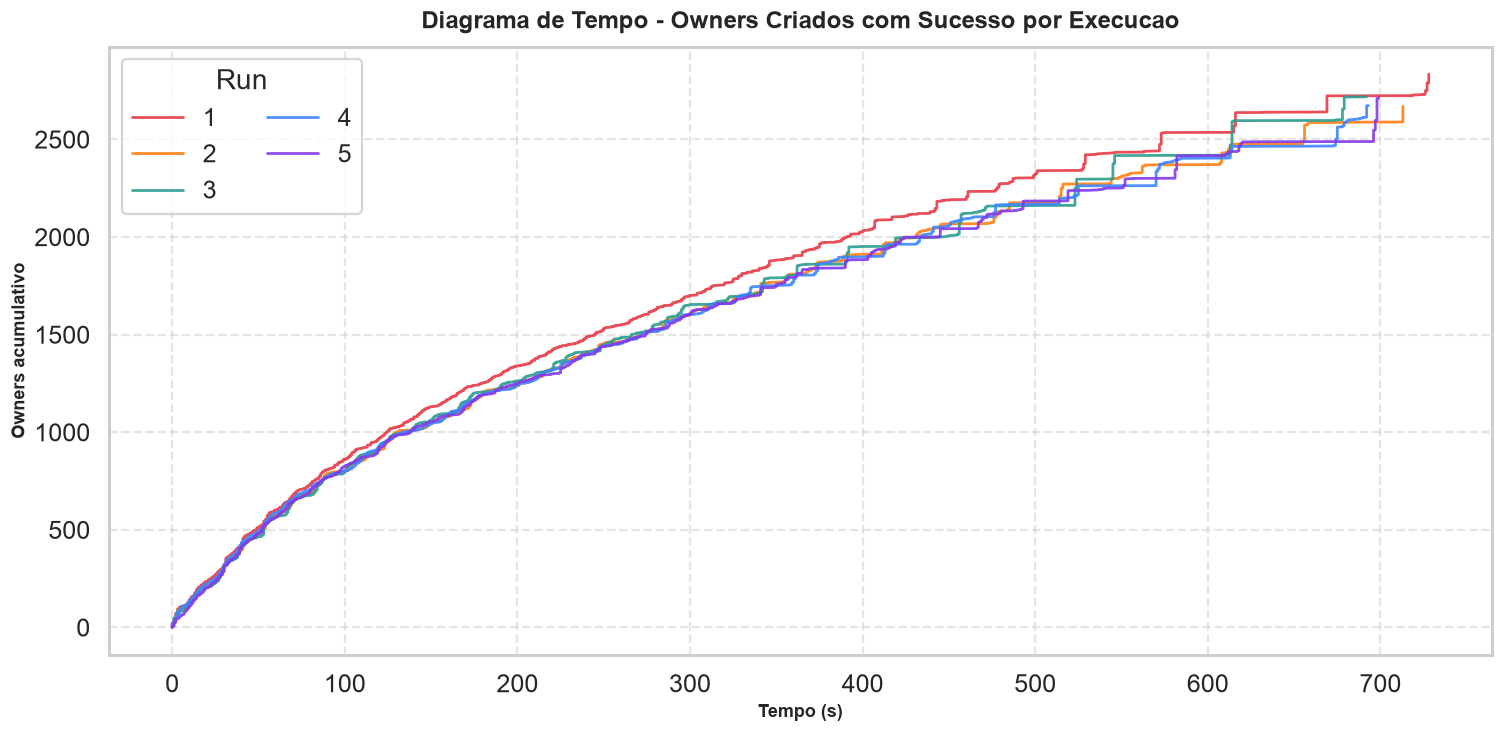

<div style='font-size:0.85em;color:#555;margin-top:4px'><i>Figura 10 - Evolucao temporal da contagem cumulativa de owners criados com sucesso no endpoint POST /owners, separada por execucao (run).</i></div>

Figura salva em: /home/diogomasc/Documentos/workspace/ws-ifba/tcc-estudo-de-caso/resultados_estatisticos_uv26/figura_10_owners_cumulativo_tempo.png


In [36]:
# Executa a analise para o cenario desejado e salva os resultados
cenario_analise = "degradada"
branch_base = SCENARIOS[cenario_analise]["k6_csv_glob"].split("/")[-1].split("_run_")[0]
print(f"Cenario analisado: {SCENARIOS[cenario_analise]['label']} ({cenario_analise})")
print(f"Branch/dataset considerado: {branch_base}")

df_owners_cumulativo = contagem_cumulativa_owners_criados(dados_k6, cenario=cenario_analise)

display(Markdown("#### Contagem cumulativa de owners criados com sucesso (POST /owners)"))
display(df_owners_cumulativo.head(20))
print(f"Total de linhas: {len(df_owners_cumulativo):,}")

csv_out = OUTPUT_DIR / "tabela_12_owners_cumulativo_degradada.csv"
xlsx_out = OUTPUT_DIR / "tabela_12_owners_cumulativo_degradada.xlsx"
fig_out = OUTPUT_DIR / "figura_10_owners_cumulativo_tempo.png"

df_owners_cumulativo.to_csv(csv_out, index=False)
df_owners_cumulativo.to_excel(xlsx_out, index=False, sheet_name="OwnersCumulativo")

print(f"CSV salvo em: {csv_out.resolve()}")
print(f"XLSX salvo em: {xlsx_out.resolve()}")

if df_owners_cumulativo.empty:
    print("Sem dados para plotar o diagrama de tempo.")
else:
    plt.figure(figsize=(14, 7))
    paleta_runs = ["#e63946", "#ff7f11", "#2a9d8f", "#3a86ff", "#8338ec"]
    sns.lineplot(
        data=df_owners_cumulativo,
        x="Tempo (s)",
        y="owners_cumulativo",
        hue="run",
        estimator=None,
        palette=paleta_runs,
        linewidth=1.8,
        alpha=0.9,
        legend="full",
    )
    plt.title("Diagrama de Tempo - Owners Criados com Sucesso por Execucao", fontsize=16, pad=12)
    plt.xlabel("Tempo (s)", fontsize=12, fontweight="bold")
    plt.ylabel("Owners acumulativo", fontsize=12, fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(title="Run", ncol=2)
    plt.tight_layout()
    plt.savefig(fig_out, dpi=300)
    plt.show()
    legenda("Figura 10 - Evolucao temporal da contagem cumulativa de owners criados com sucesso no endpoint POST /owners, separada por execucao (run).")
    print(f"Figura salva em: {fig_out.resolve()}")